# LungSeg — Multi-source lung-field segmentation with reproducible evaluation

This notebook trains and audits a lung-field segmentation pipeline for chest X-ray images. The baseline is a U-Net++ decoder with an EfficientNet-B0 encoder; optional auxiliary segmentation heads provide deep supervision, and an additional boundary head supplies a local contour-aware loss. The training objective combines Tversky and focal losses, with boundary BCE enabled by configuration. Exponential moving average (EMA), image-level metrics, surface-distance metrics, uncertainty probes, source-held-out experiments, and TorchScript export are implemented around that core model.

The data are assembled from eight logical source labels, but those labels do not represent eight independent acquisition domains. In particular, the four COVID-19 subsets are grouped under one dataset campaign, while the Darwin repackaging contains automatically generated masks and carries residual overlap risk. The manifest therefore tracks provenance and duplicate groups alongside the image/mask pairs.

## What this revision actually addresses

The notebook includes explicit checks for several failure modes that can materially change segmentation results: TTA predictions must be mapped back into the original image coordinates before averaging; HD95 and ASSD are computed between mask surfaces rather than between foreground regions; split ordering uses stable hashes rather than Python's process-salted `hash()`; empty-mask cases remain visible in the metric output; failed pretrained-weight initialization is recorded; resumable checkpoints contain optimizer and RNG state; and QC-failed cases are flagged rather than silently removed from evaluation.

It also implements duplicate-aware splitting, per-sample augmentation seeding, configurable resizing and normalization, validation-based threshold selection, an experimental uncertainty analysis, source-held-out training, post-processing comparison, and TorchScript parity checks. These are implementation capabilities, not evidence that every experiment has already been run at full research budget.

## Reading the results

The central questions are whether the composite objective improves lung boundaries, whether performance transfers across datasets with different acquisition and annotation characteristics, and whether the pipeline can identify cases that deserve manual review. Those questions need to be answered from the relevant validation and held-out results; passing the notebook's self-tests only checks selected implementation properties. In particular, the TTA and post-processing comparisons below reuse the test subset, so they should be treated as exploratory analyses rather than as independent, untouched final confirmation.

Run the notebook top to bottom in a compatible environment. The smoke configuration checks the pipeline with a small compute budget; use the `gpu_full` preset and the complete planned experiment matrix for substantive comparisons. Record the configuration, data manifest, environment, and seed with every reported result.

## 1 · Experiment configuration and reproducibility

`ExpConfig` holds the settings that define a run: data split policy, input size and preprocessing, architecture and encoder, loss switches and weights, optimizer schedule, checkpoint selection, and compute budget. The configuration is serialized to `run_config.json` and hashed so that the saved weights and tables can be tied to a specific set of choices. Presets such as A0–A3 change configuration fields instead of maintaining separate copies of the training loop.

Randomness is made explicit at the points where it affects the experiment. Source-level ordering uses stable `crc32` values and content identity uses SHA-256; Python's built-in `hash()` is avoided because its value can differ between processes. Augmentation has its own sample/epoch seed in the data path described in §7.

The validation split is used to choose a checkpoint and operating threshold. A held-out-source run is defined by `cfg.holdout`: it can exclude one source, a label tier, or a domain group from training. The distinction matters because source labels are not all independent domains. The later TTA and post-processing sections also inspect the nominal test subset; their results are therefore exploratory and must not be presented as a clean, once-only final test.

In [10]:
from dataclasses import dataclass, field, asdict
import hashlib, json, math, os, random, time, zlib
from pathlib import Path

import numpy as np

ALL_SOURCE_NAMES = ("montgomery", "shenzhen", "jsrt", "covid", "covid_opacity",
                    "covid_normal", "covid_vp", "darwin")

def stable_hash(name: str) -> int:
    """Process-independent replacement for salted builtin hash()."""
    return zlib.crc32(name.encode("utf-8"))

def sha256_file(path, buf=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(buf)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

@dataclass
class ExpConfig:
    seed: int = 42
    run_mode: str = "auto"                # auto | gpu_full | fast | smoke
    caps: dict = field(default_factory=dict)   # per-source cap; {} = everything
    exclude_sources: tuple = ()           # for composition experiments (RQ1)
    val_fraction: float = 0.15
    test_fraction: float = 0.15
    min_eval_per_source: int = 2
    use_dedup: bool = True
    phash_hamming: int = 4                # near-duplicate hamming threshold (64-bit dHash)
    qc_drop_from_train: bool = True       # QC-FAIL: dropped from train, KEPT in eval (flagged)
    holdout: str = ""                     # Protocol B: source | tier:tier | group:name
    # ---- preprocessing ----
    img_size: int = 224
    resize_mode: str = "stretch"          # stretch (original baseline) | pad
    norm_mode: str = "zero_one"           # zero_one (baseline) | train_stats | imagenet_gray
    # ---- model ----
    arch: str = "unetplusplus"
    encoder: str = "efficientnet-b0"
    encoder_weights: str = "imagenet"
    # ---- loss ablation A0..A3 ----
    use_aux: bool = True
    use_boundary: bool = True
    aux_weights: tuple = (0.5, 0.35, 0.25)
    boundary_weight: float = 0.25
    # ---- training ----
    epochs: int = 12
    batch_size: int = 32
    lr: float = 3e-4
    weight_decay: float = 1e-4
    warmup_frac: float = 0.3
    grad_clip: float = 1.0
    ema_decay: float = 0.999
    ema_warmup: int = 50
    num_workers: int = 2
    amp: str = "auto"                     # auto | on | off
    use_deterministic_algorithms: bool = False
    # ---- evaluation ----
    thresholds: tuple = tuple(round(0.30 + 0.05 * i, 2) for i in range(14))
    bootstrap_iters: int = 2000
    tta_subset: int = 400
    postproc_subset: int = 200

# Experiment matrix: each preset is a complete, reproducible configuration.
_PRESETS_BASE = {
    "gpu_full": dict(run_mode="gpu_full", epochs=12, batch_size=32, img_size=224,
                     caps={"covid": 1500, "covid_normal": 1500, "covid_opacity": 1500,
                           "covid_vp": 750, "darwin": 2000}, tta_subset=400),
    "fast":     dict(run_mode="fast", epochs=4, batch_size=16, img_size=192,
                     caps={"covid": 400, "covid_normal": 400, "covid_opacity": 400,
                           "covid_vp": 200, "darwin": 500}, tta_subset=120, postproc_subset=80),
    "smoke":    dict(run_mode="smoke", epochs=1, batch_size=4, img_size=128,
                     caps={s: 6 for s in ALL_SOURCE_NAMES}, tta_subset=8, postproc_subset=8,
                     bootstrap_iters=200, num_workers=0),
}
_VARIANTS = {
    "A0_no_aux_no_boundary": dict(use_aux=False, use_boundary=False),
    "A1_aux_only":           dict(use_aux=True,  use_boundary=False),
    "A2_boundary_only":      dict(use_aux=False, use_boundary=True),
    "A3_aux_and_boundary":   dict(use_aux=True,  use_boundary=True),
    "arch_unet":             dict(arch="unet"),
    "arch_manet":            dict(arch="manet"),
    "encoder_densenet121":   dict(encoder="densenet121"),
    "norm_train_stats":      dict(norm_mode="train_stats"),
    "norm_imagenet_gray":    dict(norm_mode="imagenet_gray"),
    "resize_pad":            dict(resize_mode="pad"),
    "train_curated_only":    dict(exclude_sources=("covid", "covid_opacity", "covid_normal",
                                                   "covid_vp", "darwin")),
    "train_no_weak":         dict(exclude_sources=("darwin",)),
}
PRESETS = {**_PRESETS_BASE}
for _k, _v in _VARIANTS.items():
    PRESETS[_k] = {**_PRESETS_BASE["gpu_full"], **_v}   # variants inherit the gpu_full budget

def resolve_config(preset: str, overrides: dict | None = None) -> ExpConfig:
    if preset == "auto":
        try:
            import torch as _t
            preset = "gpu_full" if _t.cuda.is_available() else "smoke"
        except Exception:
            preset = "smoke"
    merged = dict(PRESETS[preset])
    if overrides:
        merged.update(overrides)
    return ExpConfig(**merged)

def config_snapshot(cfg: ExpConfig, path: Path) -> str:
    d = asdict(cfg)
    d["thresholds"] = list(d["thresholds"])
    d["aux_weights"] = list(d["aux_weights"])
    blob = json.dumps(d, indent=2, sort_keys=True)
    path.write_text(blob)
    return hashlib.sha256(blob.encode()).hexdigest()[:16]

SELFTESTS: dict = {}          # name -> {"passed": bool, "detail": str}
RUN_RECORD: dict = {}         # machine-readable run facts, dumped at the end

def register_test(name, passed, detail=""):
    SELFTESTS[name] = {"passed": bool(passed), "detail": str(detail)[:300]}
    print(f"[selftest] {'PASS' if passed else 'FAIL'}  {name}  {str(detail)[:120]}")

RUN_MODE = os.environ.get("LS_RUN_MODE", "auto")
PRESET_NAME = RUN_MODE if RUN_MODE in PRESETS else "auto"
cfg = resolve_config(PRESET_NAME, overrides={"holdout": os.environ.get("LS_HOLDOUT", "")})
print(f"preset={PRESET_NAME} -> run_mode={cfg.run_mode}")


preset=auto -> run_mode=gpu_full


## 2 · Runtime environment and deterministic execution

The environment probe records the Python and library versions, hardware availability, and relevant runtime details before the experiment is interpreted. Seeds are initialized centrally, while reproducibility of augmentation is handled locally in the dataset pipeline rather than relying only on global NumPy or PyTorch seeds. This distinction is important with multi-worker data loading and transforms that maintain internal random-number generators.

The run record is part of the experiment output: weights without their configuration and environment are not enough to reproduce a result. Determinism is still bounded by the installed libraries, device kernels, and runtime settings; the resume test verifies the implemented training path under the same execution environment, not bitwise equivalence across arbitrary machines or software versions.

In [11]:
import platform, sys as _sys
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU = DEVICE.type == "cuda"
AMP = (cfg.amp == "on") or (cfg.amp == "auto" and GPU)
if GPU:
    torch.backends.cudnn.benchmark = True
if cfg.use_deterministic_algorithms:
    torch.use_deterministic_algorithms(True, warn_only=True)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if GPU:
        torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed)

def seed_worker(worker_id):
    """DataLoader worker seeding (python & numpy inside workers)."""
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

RUN_RECORD["environment"] = {
    "python": platform.python_version(), "torch": torch.__version__,
    "cuda_build": torch.version.cuda, "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if GPU else "cpu",
    "cpu_count": os.cpu_count(), "amp": AMP, "preset": PRESET_NAME,
}
WORK = Path("/kaggle/working") if os.path.isdir("/kaggle/working") else Path("ls_outputs")
WORK.mkdir(parents=True, exist_ok=True)
CFG_SHA = config_snapshot(cfg, WORK / "run_config.json")
RUN_RECORD["config_sha256_16"] = CFG_SHA
RUN_RECORD["config"] = asdict(cfg)

print(f"python  : {platform.python_version()}")
print(f"torch   : {torch.__version__}  | CUDA build: {torch.version.cuda}")
print(f"device  : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if GPU else ""))
print(f"amp     : {AMP} | workers={cfg.num_workers} | preset={PRESET_NAME}")
print(f"workdir : {WORK.resolve()} | config sha16={CFG_SHA}")


python  : 3.13.15
torch   : 2.11.0+cu130  | CUDA build: 13.0
device  : cuda (Tesla T4)
amp     : True | workers=2 | preset=auto
workdir : /content/ls_outputs | config sha16=fbcd6b6ec2997b68


## 3 · Dataset assembly and annotation provenance

The notebook obtains its source data through `kagglehub` and converts them into a common image–mask representation. There are four download references and eight logical source labels. These labels describe how the files are organized; they should not automatically be interpreted as independent external domains.

| Domain group | Logical sources | Interpretation for evaluation |
|---|---|---|
| `montgomery` | `montgomery` | Montgomery County chest radiographs with curated/radiologist lung masks. |
| `shenzhen` | `shenzhen` | Shenzhen chest radiographs with curated/radiologist lung masks. |
| `jsrt` | `jsrt` | JSRT radiographs with curated reference masks. |
| `covid_db` | `covid`, `covid_opacity`, `covid_normal`, `covid_vp` | Related subsets from one COVID-19 database/campaign; treat the group as one domain in source-held-out experiments. |
| `darwin_repackaged` | `darwin` | Third-party repackaging with auto-generated masks. Possible cross-source overlap remains a provenance risk even after duplicate checks. |

Mask provenance is stored as a tier (`curated`, `clinical`, or `weak`) and carried into the manifest. That tier is relevant to interpretation: a model may be penalized for disagreeing with a weak pseudo-mask even when the disagreement is not necessarily a true anatomical error. Exact duplicates can be detected from file contents, but a clean duplicate audit cannot prove that two differently encoded images do not depict the same patient or acquisition. No patient identity is inferred where the source does not provide it.

In [12]:
import cv2
import pandas as pd
import kagglehub

COVID_REF = "tawsifurrahman/covid19-radiography-database"
DARWIN_REF = "sawravturjo/chest-x-ray-with-masks-montgomery-shenzhen-darwin"

SOURCES = {
    "montgomery":    {"ref": "heyoujue/lungsegmentation", "tier": "curated",
                      "domain_group": "montgomery", "mask_provenance": "radiologist"},
    "shenzhen":      {"ref": "heyoujue/lungsegmentation", "tier": "curated",
                      "domain_group": "shenzhen", "mask_provenance": "radiologist"},
    "jsrt":          {"ref": "abduzzami/jsrt-247-image-lung-segmentation-mask-dataset",
                      "tier": "curated", "domain_group": "jsrt",
                      "mask_provenance": "radiologist (SCCN)"},
    "covid":         {"ref": COVID_REF, "tier": "clinical", "domain_group": "covid_db",
                      "sub": "COVID", "mask_provenance": "campaign-annotated"},
    "covid_opacity": {"ref": COVID_REF, "tier": "clinical", "domain_group": "covid_db",
                      "sub": "Lung_Opacity", "mask_provenance": "campaign-annotated"},
    "covid_normal":  {"ref": COVID_REF, "tier": "clinical", "domain_group": "covid_db",
                      "sub": "Normal", "mask_provenance": "campaign-annotated"},
    "covid_vp":      {"ref": COVID_REF, "tier": "clinical", "domain_group": "covid_db",
                      "sub": "Viral Pneumonia", "mask_provenance": "campaign-annotated"},
    "darwin":        {"ref": DARWIN_REF, "tier": "weak", "domain_group": "darwin_repackaged",
                      "mask_provenance": "auto-generated (weak)"},
}
ALL_SOURCES = tuple(SOURCES)

def download_source(name, quiet=False):
    if os.environ.get("LS_SYNTHETIC") == "1":
        return _synthetic_root()                       # offline self-test path (§4 helper)
    p = Path(kagglehub.dataset_download(SOURCES[name]["ref"]))
    if not quiet:
        print(f"[datahub] {name}: kagglehub -> {p}")
    return p

# ---------------- indexers: (image, mask) pairing per source ----------------
def _index_heyoujue(base):
    img_dir, mask_dir = base / "CXR_png", base / "masks"
    if not (img_dir.is_dir() and mask_dir.is_dir()):
        img_dir = next(base.rglob("CXR_png"), None)
        mask_dir = next(base.rglob("masks"), None) if img_dir else None
    rows = []
    if not (img_dir and mask_dir and img_dir.is_dir() and mask_dir.is_dir()):
        return rows
    masks = {p.stem.replace("_mask", ""): p for p in mask_dir.rglob("*.png")}
    for ip in sorted(img_dir.rglob("*.png")):
        mp = masks.get(ip.stem)
        if mp is None:
            continue
        src = "montgomery" if ip.stem.upper().startswith("MC") else "shenzhen"
        rows.append({"case_id": f"{src}/{ip.stem}", "path_img": str(ip),
                     "path_mask": str(mp), "source": src})
    return rows

def _filter_source(rows, name):
    return [r for r in rows if r["source"] == name]

def _index_jsrt(base):
    # match on the FINAL directory name only: the dataset name itself contains 'mask'
    imgs, masks = {}, {}
    for p in sorted(base.rglob("*.png")):
        parent = p.parent.name.lower()
        stem = p.stem.lower()
        is_mask = ("mask" in stem) or ("label" in stem) or \
                  any(k in parent for k in ("mask", "label", "seg"))
        (masks if is_mask else imgs)[stem.replace("_mask", "")] = p
    return [{"case_id": f"jsrt/{k}", "path_img": str(ip), "path_mask": str(masks[k]),
             "source": "jsrt"} for k, ip in sorted(imgs.items()) if k in masks]

def _index_covid_class(base, sub, source):
    root = base / "COVID-19_Radiography_Dataset" / sub
    if not root.is_dir():
        root = base / sub
    img_dir, mask_dir = root / "images", root / "masks"
    if not (img_dir.is_dir() and mask_dir.is_dir()):
        return []
    msk = {p.stem: p for p in mask_dir.glob("*.png")}
    return [{"case_id": f"{source}/{ip.stem}", "path_img": str(ip),
             "path_mask": str(msk[ip.stem]), "source": source}
            for ip in sorted(img_dir.glob("*.png")) if ip.stem in msk]

def _index_darwin(base):
    darwin = None
    for cand in base.rglob("Darwin"):
        if (cand / "img").is_dir():
            darwin = cand
            break
    if darwin is None:
        return []
    msk = {p.stem: p for p in (darwin / "mask").glob("*.png")}
    return [{"case_id": f"darwin/{ip.stem}", "path_img": str(ip),
             "path_mask": str(msk[ip.stem]), "source": "darwin"}
            for ip in sorted((darwin / "img").glob("*.png")) if ip.stem in msk]

def index_source(name, base=None):
    base = base if base is not None else download_source(name, quiet=True)
    if name in ("montgomery", "shenzhen"):
        return _filter_source(_index_heyoujue(base), name)
    if name == "jsrt":
        return _index_jsrt(base)
    if name.startswith("covid"):
        return _index_covid_class(base, SOURCES[name]["sub"], name)
    if name == "darwin":
        return _index_darwin(base)
    raise KeyError(name)


## 4 · Manifest, content identity, and duplicate groups

The manifest is the persistent record connecting each image and mask to its source, domain group, supervision tier, dimensions, quality-control status, and split. Full-file SHA-256 values identify byte-for-byte duplicates. The perceptual `dhash_img` adds a second, approximate check for visually similar copies after resizing or recompression; pairs within the configured Hamming-distance threshold are joined into duplicate groups.

A union-find structure combines exact and near-duplicate relationships into `dup_group`. Splitting those groups as units prevents a detected duplicate from appearing in both training and evaluation. It does not guarantee patient-level separation: the sources generally lack a shared patient identifier, and perceptual hashing can miss transformed or cropped copies. The `mask_conflict` field flags cases where identical image bytes are associated with different mask bytes, instead of arbitrarily treating one annotation as authoritative.

This CSV should be retained with every run. It is the audit trail for where each metric row came from and for checking whether a reported source-level difference might instead reflect duplicated images, annotation provenance, or unequal data composition.

In [13]:
from concurrent.futures import ThreadPoolExecutor

# ---------------- synthetic corpus (offline self-test path; LS_SYNTHETIC=1) ----------------
def _synthetic_root():
    global _SYNTH_ROOT
    try:
        return _SYNTH_ROOT
    except NameError:
        pass
    rng = np.random.RandomState(0)
    root = WORK / "synthetic_corpus"
    styles = {"montgomery": 0, "shenzhen": 1, "jsrt": 2, "covid": 3, "covid_opacity": 4,
              "covid_normal": 5, "covid_vp": 6, "darwin": 7}
    for src, k in styles.items():
        idir, mdir = root / src / "img", root / src / "mask"
        idir.mkdir(parents=True, exist_ok=True)
        mdir.mkdir(parents=True, exist_ok=True)
        n = 9 if src not in ("covid", "covid_opacity", "covid_normal", "covid_vp", "darwin") else 7
        for i in range(n):
            H, W = 256 + 16 * ((i + k) % 3), 256 + 16 * ((i + 2 * k) % 3)   # odd sizes too
            yy, xx = np.mgrid[0:H, 0:W]
            ang = np.deg2rad((i * 47 + k * 13) % 360)      # per-image gradient direction
            img = (40 + 6 * k + 55 * (np.cos(ang) * xx / max(1, W - 1)
                                      + np.sin(ang) * yy / max(1, H - 1))).clip(0, 255)
            img = img.astype(np.uint8)
            cx, cy = W * (0.34 + 0.05 * ((i % 3) - 1)), H * 0.5
            r1, r2 = H * 0.26, W * 0.11
            lung = (((yy - cy) / r1) ** 2 + ((xx - cx) / r2) ** 2 < 1.0)
            lung |= (((yy - cy) / r1) ** 2 + ((xx - (W - cx)) / r2) ** 2 < 1.0)
            img[lung] += 45                                                  # radiolucent lungs
            img += rng.randint(0, 12, (H, W)).astype(np.uint8)               # noise
            if k == 7 and i == 0:
                lung = np.zeros_like(lung)                                   # QC-FAIL: empty mask
            msk = (lung * 255).astype(np.uint8)
            cv2.imwrite(str(idir / f"{src}_{i:03d}.png"), img)
            cv2.imwrite(str(mdir / f"{src}_{i:03d}.png"), msk)
        if k == 7:  # near-duplicate of shenzhen_000 (recompressed + slightly scaled)
            ref = root / "shenzhen" / "img" / "shenzhen_000.png"
            im = cv2.imread(str(ref), cv2.IMREAD_GRAYSCALE)
            im2 = cv2.resize(im, (int(im.shape[1] * 0.9), int(im.shape[0] * 0.9)))
            ok, buf = cv2.imencode(".jpg", im2, [cv2.IMWRITE_JPEG_QUALITY, 60])
            im3 = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
            cv2.imwrite(str(root / "darwin" / "img" / "darwin_dup.png"), im3)
            m2 = cv2.imread(str(root / "shenzhen" / "mask" / "shenzhen_000.png"),
                            cv2.IMREAD_GRAYSCALE)
            m3 = cv2.resize(m2, (im3.shape[1], im3.shape[0]),
                            interpolation=cv2.INTER_NEAREST)
            cv2.imwrite(str(root / "darwin" / "mask" / "darwin_dup.png"), m3)
    _SYNTH_ROOT = root
    return root

def _synthetic_index_source(name, base):
    rows = []
    for ip in sorted((base / name / "img").glob("*.png")):
        mp = base / name / "mask" / ip.name
        if mp.exists():
            rows.append({"case_id": f"{name}/{ip.stem}", "path_img": str(ip),
                         "path_mask": str(mp), "source": name})
    return rows

# ---------------- perceptual hash (dHash 64-bit) ----------------
def dhash64(path, size=8):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (size + 1, size))
    diff = img[:, 1:] > img[:, :-1]              # horizontal gradient bits
    v = 0
    for bit in diff.flatten():
        v = (v << 1) | int(bit)
    return v

def hamming64(a, b):
    return bin(a ^ b).count("1")

class _UnionFind:
    def __init__(self):
        self.p = {}
    def find(self, x):
        self.p.setdefault(x, x)
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[ra] = rb

def build_manifest(sources=ALL_SOURCES, caps=None, use_dedup=True, workers=None):
    caps = caps or {}
    workers = workers or max(1, min(8, (os.cpu_count() or 2)))
    synthetic = os.environ.get("LS_SYNTHETIC") == "1"
    rows, roots = [], {}
    for name in sources:
        base = download_source(name, quiet=True)
        roots[name] = base
        r = _synthetic_index_source(name, base) if synthetic else index_source(name, base)
        print(f"[datahub] {name}: {len(r)} pairs")
        rows.extend(r)
    if not rows:
        raise RuntimeError("no pairs indexed — check kagglehub connectivity")
    df = pd.DataFrame(rows)
    df["tier"] = df["source"].map(lambda s: SOURCES[s]["tier"])
    df["domain_group"] = df["source"].map(lambda s: SOURCES[s]["domain_group"])
    df["mask_provenance"] = df["source"].map(lambda s: SOURCES[s]["mask_provenance"])

    # per-source cap AFTER a stable, seeded permutation (crc32 — reproducible per run)
    kept = []
    for name, g in df.groupby("source", sort=False):
        g = g.sample(frac=1.0, random_state=cfg.seed + stable_hash(name)).reset_index(drop=True)
        cap = int(caps.get(name, 0) or 0)
        if cap > 0:
            g = g.head(cap)
        kept.append(g)
    df = pd.concat(kept, ignore_index=True)

    # ---- integrity: dims, sha256 (full file), dhash ----
    def probe(r):
        img = cv2.imread(r["path_img"], cv2.IMREAD_GRAYSCALE)
        msk = cv2.imread(r["path_mask"], cv2.IMREAD_GRAYSCALE)
        return {
            "case_id": r["case_id"],
            "img_w": 0 if img is None else img.shape[1], "img_h": 0 if img is None else img.shape[0],
            "mask_w": 0 if msk is None else msk.shape[1], "mask_h": 0 if msk is None else msk.shape[0],
            "sha256_img": sha256_file(r["path_img"]) if img is not None else "unreadable",
            "sha256_mask": sha256_file(r["path_mask"]) if msk is not None else "unreadable",
            "dhash_img": dhash64(r["path_img"]),
        }
    with ThreadPoolExecutor(max_workers=workers) as ex:
        probes = list(ex.map(probe, (r for _, r in df.iterrows())))
    df = df.merge(pd.DataFrame(probes), on="case_id", how="left")

    # ---- duplicate groups (exact by sha256, near by dhash within prefix buckets) ----
    uf = _UnionFind()
    if use_dedup:
        for h, g in df.groupby("sha256_img"):
            ids = list(g["case_id"])
            for other in ids[1:]:
                uf.union(ids[0], other)
        df["bucket"] = df["dhash_img"].map(lambda v: -1 if v is None else (v >> 40))
        for _, g in df[df["bucket"] >= 0].groupby("bucket"):
            items = list(zip(g["case_id"], g["dhash_img"]))
            for i in range(len(items)):
                for j in range(i + 1, len(items)):
                    if hamming64(items[i][1], items[j][1]) <= cfg.phash_hamming:
                        uf.union(items[i][0], items[j][0])
    df["dup_group"] = [uf.find(c) for c in df["case_id"]]
    # conflicting masks on identical images (excluding trivial same-mask case)
    conflict = df.groupby("sha256_img")["sha256_mask"].nunique() > 1
    df["mask_conflict"] = df["sha256_img"].map(conflict).fillna(False)
    df = df.drop(columns=[c for c in ("bucket",) if c in df.columns])

    n_multi = int((df.groupby("dup_group").size() > 1).sum())
    n_conflict = int(df["mask_conflict"].sum())
    print(f"[manifest] rows={len(df)} | multi-image dup groups={n_multi} | "
          f"mask-conflict rows={n_conflict}")
    RUN_RECORD["manifest"] = {"rows": len(df), "multi_dup_groups": n_multi,
                              "mask_conflicts": n_conflict,
                              "dedup": use_dedup, "phash_hamming": cfg.phash_hamming}
    df.to_csv(WORK / "manifest.csv", index=False)
    return df

t0 = time.time()
manifest = build_manifest(sources=[s for s in ALL_SOURCES if s not in cfg.exclude_sources],
                          caps=cfg.caps, use_dedup=cfg.use_dedup)
print(f"manifest built in {time.time()-t0:.0f}s -> {WORK/'manifest.csv'}")
manifest.groupby(["tier", "source"]).size()


Using Colab cache for faster access to the 'lungsegmentation' dataset.
[datahub] montgomery: 138 pairs
Using Colab cache for faster access to the 'lungsegmentation' dataset.
[datahub] shenzhen: 566 pairs
Using Colab cache for faster access to the 'jsrt-247-image-lung-segmentation-mask-dataset' dataset.
[datahub] jsrt: 247 pairs
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
[datahub] covid: 3616 pairs
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
[datahub] covid_opacity: 6012 pairs
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
[datahub] covid_normal: 10192 pairs
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
[datahub] covid_vp: 1345 pairs
Using Colab cache for faster access to the 'chest-x-ray-with-masks-montgomery-shenzhen-darwin' dataset.
[datahub] darwin: 6106 pairs
[manifest] rows=8201 | multi-image dup groups=395 | mask-conflict rows=6
m

tier      source       
clinical  covid            1500
          covid_normal     1500
          covid_opacity    1500
          covid_vp          750
curated   jsrt              247
          montgomery        138
          shenzhen          566
weak      darwin           2000
dtype: int64

## 5 · Mask quality-control checks

`qc_gate` applies geometric and file-level checks to each reference mask: readability, empty masks, image/mask shape agreement, binary values, foreground area fraction, connected-component count, approximate left–right symmetry, and whether the mask touches an image border. A case is labelled PASS, WARN, or FAIL; a hard violation or multiple soft violations triggers FAIL. Border contact is treated as an informative signal rather than proof of an invalid label.

These rules are intended to catch malformed inputs and unusually shaped masks before they distort training. They do not assess anatomical correctness. A plausible area and symmetric contour can still be wrong, while a real radiograph can legitimately violate a simple geometric heuristic.

QC-FAIL cases are excluded from training but retained in evaluation with their status recorded. Results should therefore be inspected both with all evaluation rows and with FAIL rows excluded, so the quality gate does not quietly improve the headline score by deleting difficult cases. Estimating the gate's false-rejection rate requires a separately reviewed sample; that manual calibration has not been supplied by this notebook and remains open work.

In [14]:
from scipy import ndimage as ndi

def qc_gate(mask, img_shape=None, area_min=0.05, area_max=0.65, area_hard_min=0.02,
            area_hard_max=0.85, max_components=4, fail_components=12, symmetry_min=0.35):
    """Rule-based mask sanity. Returns dict(level, reasons, features...)."""
    m = (mask > 0).astype(np.uint8) if mask is not None else None
    reasons, feats = [], {}
    if m is None:
        return {"level": "FAIL", "reasons": "unreadable", "area_fraction": np.nan,
                "n_components": -1, "symmetry_iou": np.nan, "nonbinary": False,
                "shape_mismatch": False, "border_touch": False}
    area = float(m.mean())
    lab, n = ndi.label(m)
    hard_bad = area < area_hard_min or area > area_hard_max
    nonbinary = bool(mask.max() not in (0, 1) and len(np.unique(mask)) > 2)
    shape_mismatch = img_shape is not None and tuple(mask.shape) != tuple(img_shape)
    if area < area_min: reasons.append(f"area {area:.3f}<{area_min}")
    if area > area_max: reasons.append(f"area {area:.3f}>{area_max}")
    if n > max_components: reasons.append(f"components {n}>{max_components}")
    sym = np.nan
    if area > 0:
        h, w = m.shape
        left, right = m[:, :w // 2], m[:, w - w // 2:][:, ::-1]     # symmetric for odd/even w
        sym = float((left & right).sum() / max(1, (left | right).sum()))
        if sym < symmetry_min: reasons.append(f"symmetry {sym:.2f}<{symmetry_min}")
    border = bool(m[0].any() or m[-1].any() or m[:, 0].any() or m[:, -1].any())
    n_soft = len(reasons)
    level = "FAIL" if (hard_bad or n >= fail_components or n_soft >= 2) else \
            ("WARN" if n_soft == 1 else "PASS")
    return {"level": level, "reasons": "; ".join(reasons) or "ok",
            "area_fraction": area, "n_components": int(n), "symmetry_iou": sym,
            "nonbinary": nonbinary, "shape_mismatch": shape_mismatch, "border_touch": border}

def _qc_row(r):
    msk = cv2.imread(r["path_mask"], cv2.IMREAD_GRAYSCALE)
    m = msk if msk is None else ((msk > 0).astype(np.uint8) if msk.max() > 1 else msk.astype(np.uint8))
    if m is not None and max(m.shape) > 1024:                       # bounded QC compute
        s = 1024 / max(m.shape)
        m = cv2.resize(m, (int(m.shape[1] * s), int(m.shape[0] * s)),
                       interpolation=cv2.INTER_NEAREST)
    img_shape = (m.shape[0], m.shape[1]) if m is not None else None
    return {"case_id": r["case_id"], "source": r["source"], **qc_gate(m, img_shape=img_shape)}

with ThreadPoolExecutor(max_workers=max(1, min(8, (os.cpu_count() or 2)))) as ex:
    qc_rows = list(ex.map(_qc_row, (r for _, r in manifest.iterrows())))
qc_rep = pd.DataFrame(qc_rows)
manifest = manifest.merge(qc_rep[["case_id", "level", "reasons", "area_fraction",
                                  "n_components", "symmetry_iou"]]
                          .rename(columns={"level": "qc_level", "reasons": "qc_reasons"}),
                          on="case_id", how="left")
manifest.to_csv(WORK / "manifest.csv", index=False)
qc_rep.to_csv(WORK / "qc_report.csv", index=False)
print("QC levels:", qc_rep["level"].value_counts().to_dict())
RUN_RECORD["qc"] = {"levels": qc_rep["level"].value_counts().to_dict(),
                    "fail_dropped_from_train_only": cfg.qc_drop_from_train}
qc_rep.groupby("source")["level"].value_counts().unstack(fill_value=0)


QC levels: {'PASS': 6883, 'WARN': 1290, 'FAIL': 28}


level,FAIL,PASS,WARN
source,,,
covid,1,1121,378
covid_normal,0,1346,154
covid_opacity,1,936,563
covid_vp,0,651,99
darwin,26,1934,40
jsrt,0,232,15
montgomery,0,124,14
shenzhen,0,539,27


## 6 · Split design: internal evaluation and held-out domains

**Protocol A — internal split.** Within each source, the manifest's duplicate groups are shuffled with a stable seeded ordering and assigned approximately 70% / 15% / 15% to training, validation, and test. Assignment occurs at group level, not row level. Per-source allocation helps retain representation from smaller collections, but it does not make the split patient-independent where patient IDs are unavailable.

**Protocol B — held-out source or supervision group.** `cfg.holdout` can select an individual source such as `jsrt`, a supervision tier such as `tier:weak`, or a domain group such as `group:covid_db`. The selected rows are excluded from the training pool and used for the held-out evaluation; the remaining data supply the development split. The four COVID subsets must be held out together when the question concerns transfer to that campaign.

The manifest and `test_frozen.csv` make the intended split explicit before model fitting. However, a saved split is not by itself proof of a fully untouched final test: later TTA and post-processing sections compare alternatives using this test subset. Those later comparisons should be labelled exploratory, and any confirmatory model or deployment choice should be selected on validation data or on a separate development set.

In [15]:
def _match_holdout(value, row):
    if not value:
        return False
    if value.startswith("tier:"):
        return row["tier"] == value.split(":", 1)[1]
    if value.startswith("group:"):
        return row["domain_group"] == value.split(":", 1)[1]
    return row["source"] == value

def assign_splits(man, cfg):
    """Group-level split: every dup group assigned exactly once via its PRIMARY source
    (groups can span sources — e.g. a darwin repackage of a shenzhen image), so quotas
    are computed over rows grouped by primary source and applied by dup_group id."""
    man = man.copy()
    group_source = man.groupby("dup_group")["source"].first()
    man["_psrc"] = man["dup_group"].map(group_source)
    man["split"] = "train"
    for source, g in man.groupby("_psrc"):
        total = len(g)
        groups = sorted(g["dup_group"].unique())
        rng2 = np.random.RandomState(cfg.seed + stable_hash(f"split|{source}"))
        rng2.shuffle(groups)
        n_val = max(cfg.min_eval_per_source if total >= 6 else 1,
                    int(round(total * cfg.val_fraction)))
        n_test = max(cfg.min_eval_per_source if total >= 6 else 1,
                     int(round(total * cfg.test_fraction)))
        val_groups, test_groups, n_valc, n_testc = set(), set(), 0, 0
        for gid in groups:
            gsz = int((g["dup_group"] == gid).sum())
            if n_valc < n_val:
                val_groups.add(gid); n_valc += gsz
            elif n_testc < n_test:
                test_groups.add(gid); n_testc += gsz
            else:
                break
        gidx = g.index.to_numpy()
        man.loc[gidx[np.isin(g.loc[gidx, "dup_group"], list(val_groups))], "split"] = "val"
        man.loc[gidx[np.isin(g.loc[gidx, "dup_group"], list(test_groups))], "split"] = "test"
    man = man.drop(columns=["_psrc"])
    if cfg.holdout:
        hold_mask = man.apply(lambda r: _match_holdout(cfg.holdout, r), axis=1)
        held_groups = set(man.loc[hold_mask, "dup_group"])   # whole dup groups move together
        man.loc[man["dup_group"].isin(held_groups), "split"] = "test_holdout"
    # safety: no dup_group spans two splits
    spans = man.groupby("dup_group")["split"].nunique()
    assert (spans <= 1).all(), "duplicate group leaked across splits"
    return man

manifest = assign_splits(manifest, cfg)
manifest.to_csv(WORK / "manifest.csv", index=False)
manifest[manifest["split"].isin(["test", "test_holdout"])][
    ["case_id", "source", "tier", "split"]].to_csv(WORK / "test_frozen.csv", index=False)
if cfg.qc_drop_from_train:
    drop_ids = manifest.loc[(manifest["qc_level"] == "FAIL") &
                            (manifest["split"] == "train"), "case_id"]
    manifest.loc[manifest["case_id"].isin(drop_ids), "split"] = "train_qc_dropped"
print("split sizes:", manifest["split"].value_counts().to_dict())
print("per-source:", manifest[manifest["split"] == "train"].groupby("source").size().to_dict())
RUN_RECORD["splits"] = manifest["split"].value_counts().to_dict()


split sizes: {'train': 5712, 'val': 1233, 'test': 1232, 'train_qc_dropped': 24}
per-source: {'covid': 1039, 'covid_normal': 1039, 'covid_opacity': 1061, 'covid_vp': 520, 'darwin': 1382, 'jsrt': 172, 'montgomery': 98, 'shenzhen': 401}


## 7 · Preprocessing and sample-level augmentation

Images and masks pass through the same spatial transforms so the supervision remains aligned. The transform builder uses nearest-neighbour interpolation for masks, and the inline checks exercise binary-mask preservation and image/mask agreement. Training augmentation includes horizontal reflection, modest affine rotation/translation/scale changes, brightness/contrast variation, and CLAHE; each operation is intended to expose the model to plausible variation without altering the class definition.

For a given sample, augmentation seeds are derived from the global seed, epoch, and case identifier. The result is repeatable for the same `(seed, epoch, sample)` even if loader order changes. This property is useful for debugging and is part of the checkpoint-resume test, although identical results across different hardware/library combinations are not guaranteed.

Preprocessing is configurable. `resize_mode=stretch` resizes directly to a square and can distort aspect ratio; `pad` preserves aspect ratio and pads to the model canvas, with the padding geometry retained for mapping predictions back. `norm_mode` supports `[0,1]` scaling, statistics calculated from training data, or ImageNet-style single-channel normalization. Validation/test data must use training-derived statistics rather than estimate their own.

One source contains images and masks stored at different pixel dimensions (including a COVID subset with 299×299 images and 256×256 masks). The pipeline aligns both to the configured model size because they represent the same field of view; shape checking is disabled at the augmentation boundary for that documented case, rather than assuming the raw arrays already have matching dimensions.

In [16]:
import albumentations as A

def build_transforms(size, train, cfg=None):
    """stretch = direct Resize (original baseline). pad = LongestMaxSize + zero-pad,
    aspect preserved; the pad box is recoverable from original dims (dataset meta)."""
    cfg = cfg or globals()["cfg"]
    if cfg.resize_mode == "pad":
        spatial = [A.LongestMaxSize(size),
                   A.Pad(size, size, position="top_left",
                         border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0)]
    else:
        spatial = [A.Resize(size, size)]
    if train:
        return A.Compose(spatial + [
            A.HorizontalFlip(p=0.5),
            A.Affine(translate_percent=(-0.05, 0.05), scale=(0.9, 1.1),
                     rotate=(-10, 10), p=0.7),
            A.RandomBrightnessContrast(0.15, 0.15, p=0.4),
            A.CLAHE(clip_limit=2.0, p=0.2),
        ], is_check_shapes=False)   # covid subset ships 299^2 img / 256^2 mask, same FOV
    return A.Compose(spatial, is_check_shapes=False)

def _seed_transforms(tf, h):
    """Per-sample determinism: albu 2.x keeps internal RNGs; set them explicitly.
    Falls back gracefully on other albu versions (documented in AUDIT_REPORT)."""
    try:
        for t in tf.transforms:
            t.set_random_seed(h)
    except Exception:
        random.seed(h); np.random.seed(h % 2**32)

# ---- normalization strategies (Phase 4.2): stats from TRAIN only ----
def compute_train_stats(man, n_max=2000, size=64):
    tr = man[man["split"] == "train"]
    sample = tr.sample(min(n_max, len(tr)), random_state=cfg.seed) if len(tr) > n_max else tr
    acc, n = np.zeros(2, np.float64), 0
    for _, r in sample.iterrows():
        im = cv2.imread(r["path_img"], cv2.IMREAD_GRAYSCALE)
        if im is None:
            continue
        im = cv2.resize(im, (size, size)).astype(np.float32) / 255.0
        acc += im.mean(), im.var()
        n += 1
    mean = float(acc[0] / max(1, n))
    std = float(math.sqrt(max(1e-8, acc[1] / max(1, n) - mean**2)))
    stats = {"mean": mean, "std": std}
    (WORK / "train_stats.json").write_text(json.dumps(stats, indent=2))
    return stats

NORM_STATS = compute_train_stats(manifest) if cfg.norm_mode == "train_stats" else None
IMAGENET_GRAY = {"mean": 0.449, "std": 0.226}   # single-channel ImageNet average

def normalize(img01):
    if cfg.norm_mode == "train_stats" and NORM_STATS:
        return (img01 - NORM_STATS["mean"]) / NORM_STATS["std"]
    if cfg.norm_mode == "imagenet_gray":
        return (img01 - IMAGENET_GRAY["mean"]) / IMAGENET_GRAY["std"]
    return img01                                  # zero_one baseline (as original)

class CxrSegDataset(torch.utils.data.Dataset):
    """Grayscale CXR segmentation dataset with per-sample deterministic augmentation."""
    def __init__(self, df, size, train, cfg, epoch=0):
        self.df = df.reset_index(drop=True)
        self.size, self.train, self.cfg, self.epoch = size, train, cfg, epoch
        self.tf = build_transforms(size, train, cfg)

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.imread(str(r["path_img"]), cv2.IMREAD_GRAYSCALE)
        msk = cv2.imread(str(r["path_mask"]), cv2.IMREAD_GRAYSCALE)
        if img is None or msk is None:
            raise IOError(f"unreadable: {r['path_img']}")
        orig_h, orig_w = img.shape
        if msk.max() > 1:
            msk = (msk > 127).astype(np.uint8) * 255    # darwin ships 0..3 label maps
        h = zlib.crc32(f"{self.cfg.seed}|{self.epoch}|{r['case_id']}".encode()) & 0xFFFFFFFF
        _seed_transforms(self.tf, h)
        t = self.tf(image=img, mask=msk)                # albu: bilinear img / nearest mask
        x = normalize(t["image"].astype("float32") / 255.0)
        y = (t["mask"] > 127).astype("float32")         # final binarization
        meta = {"orig_h": orig_h, "orig_w": orig_w,
                "pad": self.cfg.resize_mode == "pad"}
        return {"image": torch.from_numpy(x[None]), "mask": torch.from_numpy(y[None]),
                "case_id": r["case_id"], "source": r["source"], "tier": r["tier"],
                "qc_level": r.get("qc_level", "PASS"), "meta": json.dumps(meta)}

# ---- transform consistency validation (Phase 4.3) — runs inline ----
def validate_transforms():
    rng = np.random.RandomState(1)
    img = (np.full((96, 96), 60, np.float32) + rng.randint(0, 30, (96, 96))).astype(np.uint8)
    msk = np.zeros((96, 96), np.uint8)
    msk[24:72, 20:64] = 255
    ok_bin, ok_flip, ok_rot, ok_det = True, True, True, True
    for _ in range(10):
        tf = build_transforms(96, True, cfg)
        _seed_transforms(tf, 7)
        out = tf(image=img, mask=msk)
        if not np.isin(out["mask"], (0, 255)).all():
            ok_bin = False
    tf1 = A.Compose([A.HorizontalFlip(p=1.0)])
    o = tf1(image=img, mask=msk)
    ok_flip = np.array_equal(o["image"], np.fliplr(img)) and np.array_equal(o["mask"], np.fliplr(msk))
    tf2 = A.Compose([A.Affine(rotate=12, p=1.0)], is_check_shapes=False)
    o2 = tf2(image=img, mask=msk)
    ok_rot = np.isin(o2["mask"], (0, 255)).all()        # nearest interp for masks
    tf3 = build_transforms(96, True, cfg)
    _seed_transforms(tf3, 11); a = tf3(image=img, mask=msk)
    _seed_transforms(tf3, 11); b = tf3(image=img, mask=msk)
    ok_det = np.array_equal(a["image"], b["image"]) and np.array_equal(a["mask"], b["mask"])
    return bool(ok_bin and ok_flip and ok_rot and ok_det), \
           {"binary_mask": bool(ok_bin), "hflip_pairing": bool(ok_flip),
            "mask_nearest_rot": bool(ok_rot), "per_sample_determinism": bool(ok_det)}

ok, detail = validate_transforms()
register_test("transform_consistency", ok, json.dumps(detail))
RUN_RECORD["transform_checks"] = detail

def make_loaders(train_df, eval_dfs, cfg):
    tr = CxrSegDataset(train_df, cfg.img_size, True, cfg)
    ev = {k: CxrSegDataset(d, cfg.img_size, False, cfg) for k, d in eval_dfs.items()}
    g = torch.Generator(); g.manual_seed(cfg.seed)
    common = dict(num_workers=cfg.num_workers, pin_memory=GPU,
                  worker_init_fn=seed_worker, generator=g,
                  persistent_workers=cfg.num_workers > 0)
    from torch.utils.data import DataLoader, Sampler

    class EpochSampler(Sampler):
        """Deterministic per-epoch order: pure function of (seed, epoch)."""
        def __init__(self, n, seed, epoch):
            gg = torch.Generator(); gg.manual_seed(int(seed) * 1000003 + int(epoch))
            self.order = torch.randperm(n, generator=gg).tolist()
        def __iter__(self):
            return iter(self.order)
        def __len__(self):
            return len(self.order)

    train_loader = DataLoader(tr, batch_size=cfg.batch_size,
                              sampler=EpochSampler(len(tr), cfg.seed, 1),
                              drop_last=True, **common)
    ev_loaders = {k: DataLoader(d, batch_size=cfg.batch_size, shuffle=False, **common)
                  for k, d in ev.items()}
    return tr, ev, train_loader, ev_loaders, EpochSampler

train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
eval_dfs = {s: manifest[manifest["split"] == s].reset_index(drop=True)
            for s in ("val", "test") if (manifest["split"] == s).any()}
if "val" not in eval_dfs:
    raise RuntimeError("validation split is empty — cannot select or calibrate")
tr_ds, ev_ds, train_loader, ev_loaders, EpochSampler = make_loaders(
    train_df, eval_dfs, cfg)
print(f"datasets: train={len(tr_ds)} " +
      " ".join(f"{k}={len(v)}" for k, v in ev_ds.items()))

# ---- throughput probe (Phase 4.4): measure before optimizing ----
def throughput_probe(loader, ds, n_batches=8):
    t0 = time.time(); seen = 0; k = -1
    it = iter(loader)
    for k in range(min(n_batches, len(loader))):
        try:
            b = next(it)
        except StopIteration:
            break
        seen += b["image"].shape[0]
    dt = time.time() - t0
    nb = max(1, k + 1)
    return {"batches": nb, "images": seen, "s_per_batch": dt / nb,
            "img_per_s": seen / max(1e-9, dt)}

tp = throughput_probe(train_loader, tr_ds)
RUN_RECORD["data_throughput"] = tp
print(f"[throughput] data-only: {tp['img_per_s']:.0f} img/s "
      f"({tp['s_per_batch']*1000:.0f} ms/batch) | workers={cfg.num_workers}, "
      f"pin_memory={GPU}, persistent={cfg.num_workers>0}")


[selftest] PASS  transform_consistency  {"binary_mask": true, "hflip_pairing": true, "mask_nearest_rot": true, "per_sample_determinism": true}
datasets: train=5712 val=1233 test=1232
[throughput] data-only: 169 img/s (190 ms/batch) | workers=2, pin_memory=True, persistent=True


## 8 · Network design and initialization

`LungSegNet` uses a U-Net++-style nested decoder with an EfficientNet-B0 encoder by default. The nested skip pathways combine features from multiple decoder depths, helping the final representation retain spatial detail while incorporating deeper encoder context. Optional auxiliary heads attach to intermediate encoder features and provide deep-supervision signals during training. A separate boundary head predicts a contour-related target from the final decoder representation; it is an auxiliary objective, not a second independent segmentation model.

The architecture and encoder are configuration fields, allowing the same data path and training loop to compare alternatives such as U-Net, MAnet, or a different encoder. The construction probe records the decoder calling convention expected by the installed `segmentation_models_pytorch` version, reducing the chance that a library API difference silently changes the forward pass.

Pretrained initialization is recorded explicitly. If weights cannot be downloaded or loaded, the code warns and falls back to random initialization, and `RUN_RECORD["encoder_init"]` records that event. Such a run is not equivalent to an ImageNet-initialized run and should not be compared with one without noting the initialization difference.

In [17]:
import segmentation_models_pytorch as smp

ARCHS = {}
for _key, _cls in (("unetplusplus", "UnetPlusPlus"), ("unet", "Unet"),
                   ("manet", "MAnet"), ("fpn", "FPN"), ("deeplabv3plus", "DeepLabV3Plus")):
    if hasattr(smp, _cls):
        ARCHS[_key] = getattr(smp, _cls)

def _build_once(arch_cls, encoder, in_ch, weights):
    last = None
    for kw in ("weights", "encoder_weights"):          # smp >=0.5 vs older kwarg
        try:
            return arch_cls(encoder_name=encoder, in_channels=in_ch, classes=1,
                            **{kw: weights})
        except TypeError as e:
            last = e
    raise last

def build_seg_model(arch, encoder, in_ch, weights, record):
    try:
        m = _build_once(ARCHS[arch], encoder, in_ch, weights)
        record["encoder_init"] = f"pretrained:{weights}"
        return m
    except Exception as e:
        print(f"[model] WARNING: pretrained '{weights}' failed ({type(e).__name__}: {e}); "
              f"FALLING BACK TO RANDOM INIT — run recorded as such")
        m = _build_once(ARCHS[arch], encoder, in_ch, None)
        record["encoder_init"] = f"random_init_fallback ({type(e).__name__})"
        return m

class LungSegNet(nn.Module):
    def __init__(self, cfg, record=None):
        super().__init__()
        record = RUN_RECORD if record is None else record
        self.seg = build_seg_model(cfg.arch, cfg.encoder, 1, cfg.encoder_weights, record)
        enc_chs = self.seg.encoder.out_channels
        self.aux_heads = nn.ModuleList(nn.Conv2d(enc_chs[s], 1, 1) for s in (1, 2, 3))
        was_training = self.seg.training
        self.seg.eval()                       # BN running-stats mode for the probe batch
        with torch.no_grad():
            feats = self.seg.encoder(torch.zeros(1, 1, 32, 32))
            try:
                dec = self.seg.decoder(*feats); self._list = False
            except TypeError:
                dec = self.seg.decoder(list(feats)); self._list = True
            dch = dec.shape[1]
        if was_training:
            self.seg.train()
        self.boundary_head = nn.Sequential(
            nn.Conv2d(dch, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 3, padding=1))

    def _decode(self, f):
        return self.seg.decoder(list(f)) if self._list else self.seg.decoder(*f)

    def forward(self, x):
        size = x.shape[-2:]
        feats = self.seg.encoder(x)
        dec = self._decode(feats)
        logits = self.seg.segmentation_head(dec)
        aux = [F.interpolate(h(f), size=size, mode="bilinear", align_corners=False)
               for h, f in zip(self.aux_heads, (feats[1], feats[2], feats[3]))]
        boundary = F.interpolate(self.boundary_head(dec), size=size,
                                 mode="bilinear", align_corners=False)
        return {"logits": logits, "aux": aux, "boundary": boundary}

model = LungSegNet(cfg).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
model.eval()
with torch.no_grad():
    probe = model(torch.zeros(1, 1, cfg.img_size, cfg.img_size, device=DEVICE))
lat = []
with torch.no_grad():
    for _ in range(5):
        t0 = time.time()
        model(torch.zeros(1, 1, cfg.img_size, cfg.img_size, device=DEVICE))
        if GPU:
            torch.cuda.synchronize()
        lat.append(time.time() - t0)
RUN_RECORD["model"] = {"params": n_params, "arch": cfg.arch, "encoder": cfg.encoder,
                       "encoder_init": RUN_RECORD.get("encoder_init", "pretrained:imagenet"),
                       "fwd_latency_s": float(np.median(lat))}
print(f"model: {cfg.arch}/{cfg.encoder} params={n_params/1e6:.2f}M "
      f"init={RUN_RECORD['model']['encoder_init']} fwd={np.median(lat)*1000:.0f}ms")
print({k: tuple(v.shape) for k, v in probe.items() if k != "aux"},
      "| aux:", [tuple(a.shape) for a in probe["aux"]])


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

model: unetplusplus/efficientnet-b0 params=6.57M init=pretrained:imagenet fwd=14ms
{'logits': (1, 1, 224, 224), 'boundary': (1, 1, 224, 224)} | aux: [(1, 1, 224, 224), (1, 1, 224, 224), (1, 1, 224, 224)]


## 9 · Loss function and ablation design

The main segmentation output is optimized with the sum of Tversky and focal loss. When deep supervision is enabled, the auxiliary-head losses are added with their configured weights and the sum is normalized by `1 + Σwᵢ`. The boundary term is added separately when enabled:

```text
L = [Lmain + Σᵢ wᵢ Laux,i] / [1 + Σᵢ wᵢ] + λboundary Lboundary
Lmain, Laux,i = LTversky + LFocal
```

Tversky uses `α = 0.7` and `β = 0.3` in this implementation, weighting false-positive and false-negative terms asymmetrically. The focal component (`γ = 2`, `α = 0.25`) reduces the relative contribution of easy pixels, which otherwise dominate a foreground/background segmentation objective. These coefficients are experiment settings, not universal optima; the preferred trade-off can vary with annotation tier and threshold selection.

The boundary loss is a weighted binary cross-entropy on a morphological band of configured width (`band_px = 8` after resizing). Its positive weighting and background floor keep the contour term from becoming numerically negligible, but the effective width in original-image pixels depends on `img_size`. This is a model-space boundary surrogate, not a surface-distance loss.

A0–A3 toggle auxiliary supervision and the boundary term so their contributions can be isolated without forking the training code. The individual loss components are logged each epoch; interpretation should use the held-out metrics as well, because a lower composite training loss does not by itself establish better contours or cross-domain performance.

In [18]:
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.3, smooth=1.0):
        super().__init__()
        self.alpha, self.beta, self.smooth = alpha, beta, smooth
    def forward(self, logits, target):
        p = torch.sigmoid(logits).flatten(1); t = target.flatten(1).float()
        tp = (p * t).sum(1); fp = (p * (1 - t)).sum(1); fn = ((1 - p) * t).sum(1)
        ti = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        return 1.0 - ti.mean()

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha
    def forward(self, logits, target):
        bce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
        p = torch.sigmoid(logits)
        pt = p * target + (1 - p) * (1 - target)
        at = self.alpha * target + (1 - self.alpha) * (1 - target)
        return (at * (1 - pt) ** self.gamma * bce).mean()

class BoundaryBCE(nn.Module):
    def __init__(self, band_px=8, pos_weight=2.0, bg_floor=0.05):
        super().__init__()
        self.band_px, self.pos_weight, self.bg_floor = band_px, pos_weight, bg_floor
    def _dilate(self, m, k):
        return F.max_pool2d(m, 2 * k + 1, stride=1, padding=k)
    def _erode(self, m, k):
        return 1.0 - self._dilate(1.0 - m, k)
    def forward(self, boundary_logits, target):
        t = (target > 0.5).float()
        band = torch.clamp((t - self._erode(t, self.band_px)) +
                           (self._dilate(t, self.band_px) - t), 0.0, 1.0)
        w = self.bg_floor + (self.pos_weight - self.bg_floor) * band
        bce = F.binary_cross_entropy_with_logits(boundary_logits, band, reduction="none")
        return (bce * w).mean()

class CompositeLoss(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tv, self.fo = TverskyLoss(), FocalLoss()
        self.bb = BoundaryBCE()
        self.use_aux, self.use_boundary = cfg.use_aux, cfg.use_boundary
        self.w, self.bw = tuple(cfg.aux_weights), cfg.boundary_weight
    def _seg(self, lg, t):
        return self.tv(lg, t) + self.fo(lg, t)
    def forward(self, out, target):
        main = self._seg(out["logits"], target)
        parts = {"seg": float(main.detach())}
        total = main
        if self.use_aux:
            aux = sum(w * self._seg(lg, target) for w, lg in zip(self.w, out["aux"]))
            total = (total + aux) / (1 + sum(self.w))
            parts["aux"] = float(aux.detach())
        if self.use_boundary:
            bterm = self.bb(out["boundary"], target)
            total = total + self.bw * bterm
            parts["boundary"] = float(bterm.detach())
        parts["loss"] = float(total.detach())
        return total, parts

criterion = CompositeLoss(cfg)
with torch.no_grad():
    _, loss_parts = criterion(probe, torch.rand_like(probe["logits"]))
print("loss sanity on random input:", {k: round(v, 3) for k, v in loss_parts.items()})


loss sanity on random input: {'seg': 1.145, 'aux': 0.922, 'boundary': 1.574, 'loss': 1.377}


## 10 · Metric definitions and edge-case conventions

Metric implementation matters for lung segmentation because empty predictions, failed masks, and contour displacement can be hidden by a single overlap score. The notebook reports per-image Dice, IoU, precision, recall, and specificity and uses explicit conventions: both prediction and reference empty gives Dice/IoU of 1; a one-sided empty mask gives Dice/IoU of 0. Empty predictions are also tracked in failure-rate columns rather than silently omitted. Precision is set to 1 for an empty prediction by convention, so it must be read alongside recall, Dice, and the empty-prediction rate.

**Surface distances.** Each binary mask is reduced to a one-pixel surface (`mask XOR erode(mask)`). Directed distances are calculated from surface pixels to the other mask's surface. HD95 is the maximum of the two directed 95th percentiles; ASSD is the mean of the two directed mean distances. If both masks are empty, the distance is zero; if only one is empty, the configured image-diagonal penalty is used and the case remains counted. Distances are in pixels on the resized model grid, not millimetres: these repackaged collections do not provide sufficiently consistent spatial calibration for a defensible mm conversion.

The notebook reports macro per-image aggregation separately from sample/global aggregation, since large masks and large source collections otherwise dominate a pooled score. Bootstrap intervals resample images, which are the evaluation units here, not individual pixels. Brier score and expected calibration error (ECE) are computed at pixel level and describe probability calibration under the selected evaluation setup; they do not establish clinical calibration by themselves. Synthetic examples exercise the metric edge cases before the functions are used on model predictions.

In [19]:
from scipy import ndimage as ndi
from scipy import stats as sps

def per_image_stats(pred, gt):
    """pred/gt: HxW bool arrays. Returns dict of overlap metrics + failure flags."""
    pred = np.asarray(pred).astype(bool); gt = np.asarray(gt).astype(bool)
    p_sum, g_sum = int(pred.sum()), int(gt.sum())
    inter = int((pred & gt).sum())
    both_empty = (p_sum == 0 and g_sum == 0)
    d = {"both_empty": both_empty, "pred_empty": p_sum == 0, "gt_empty": g_sum == 0}
    if both_empty:
        dice = iou = precision = recall = specificity = 1.0
    elif p_sum == 0:                       # empty pred, nonempty gt -> total failure
        dice = iou = recall = 0.0; precision = 1.0
    elif g_sum == 0:                       # nonempty pred over empty gt
        dice = iou = precision = 0.0; recall = 1.0
    else:
        dice = 2 * inter / (p_sum + g_sum)
        iou = inter / (p_sum + g_sum - inter)
        precision = inter / p_sum
        recall = inter / g_sum
    tn = pred.size - int((pred | gt).sum())
    specificity = tn / max(1, pred.size - g_sum) if g_sum < pred.size else 1.0
    d.update(dice=dice, iou=iou, precision=precision, recall=recall, specificity=specificity)
    return d

def _boundary(m):
    b = m ^ ndi.binary_erosion(m)
    if not b.any():                        # single-pixel or full-frame mask edge cases
        b = m
    return b

def surface_distances(pred, gt):
    """Surface-to-surface HD95/ASSD in px. status explains empty handling; the caller
    is responsible for applying the diagonal penalty (kept separate for reporting)."""
    pred = np.asarray(pred).astype(bool); gt = np.asarray(gt).astype(bool)
    H, W = pred.shape
    diag = float(np.hypot(H, W))
    if not pred.any() and not gt.any():
        return {"hd95": 0.0, "assd": 0.0, "status": "both_empty", "penalty_applied": 0.0}
    if not pred.any() or not gt.any():
        return {"hd95": diag, "assd": diag, "status": "pred_empty" if not pred.any() else "gt_empty",
                "penalty_applied": diag}
    pb, gb = _boundary(pred), _boundary(gt)
    dt_to_gb = ndi.distance_transform_edt(~gb)     # distance to GT SURFACE
    dt_to_pb = ndi.distance_transform_edt(~pb)
    d_pg = dt_to_gb[pb]                            # pred surface -> gt surface
    d_gp = dt_to_pb[gb]                            # gt surface  -> pred surface
    hd95 = max(float(np.percentile(d_pg, 95)), float(np.percentile(d_gp, 95)))
    assd = 0.5 * (float(d_pg.mean()) + float(d_gp.mean()))
    return {"hd95": hd95, "assd": assd, "status": "ok", "penalty_applied": 0.0}

def brier_score(probs, targets, max_px=2_000_000, seed=0):
    p = probs.reshape(-1); y = targets.reshape(-1).astype(np.float32)
    if len(p) > max_px:
        sel = np.random.RandomState(seed).choice(len(p), max_px, replace=False)
        p, y = p[sel], y[sel]
    return float(np.mean((p - y) ** 2))

def expected_calibration_error(probs, targets, bins=15, max_px=2_000_000, seed=0):
    p = probs.reshape(-1); y = targets.reshape(-1).astype(bool)
    if len(p) > max_px:
        sel = np.random.RandomState(seed).choice(len(p), max_px, replace=False)
        p, y = p[sel], y[sel]
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)

def bootstrap_ci(values, iters=2000, seed=42):
    v = np.asarray(values, np.float64)
    if len(v) == 0:
        return float("nan"), float("nan"), float("nan")
    rng = np.random.RandomState(seed)
    k = rng.randint(0, len(v), size=(iters, len(v)))
    m = v[k].mean(1)
    return float(v.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def sample_weighted_dice(preds, gts):
    """Global intersection / global sum — the sample-weighted view."""
    pi = np.asarray(preds).astype(bool).sum(); gi = np.asarray(gts).astype(bool).sum()
    ii = (np.asarray(preds).astype(bool) & np.asarray(gts).astype(bool)).sum()
    return float(2 * ii / max(1, pi + gi))

# ---------------- inline self-tests (synthetic, run every execution) ----------------
def selftest_metrics():
    ok_all, notes = True, []
    H, W = 128, 128
    gt = np.zeros((H, W), bool); gt[24:104, 24:104] = True
    # 1. identical masks
    m = per_image_stats(gt, gt); s = surface_distances(gt, gt)
    t = (m["dice"] == 1.0 and s["hd95"] == 0.0 and s["assd"] == 0.0)
    notes.append(f"identical: dice={m['dice']}, hd95={s['hd95']:.2f}")
    ok_all &= t
    # 2. EDT-based surface distances must match an independent brute-force reference
    #    (scipy.spatial cdist between boundary coordinate sets) — validates both the
    #    surface extraction and the aggregation, on two concentric-square geometries
    from scipy.spatial.distance import cdist
    def brute_surface(pred, gt):
        pb = np.argwhere(pred ^ ndi.binary_erosion(pred))
        gb = np.argwhere(gt ^ ndi.binary_erosion(gt))
        d_pg = cdist(pb, gb).min(1)
        d_gp = cdist(gb, pb).min(1)
        return max(float(np.percentile(d_pg, 95)), float(np.percentile(d_gp, 95))), \
               0.5 * (float(d_pg.mean()) + float(d_gp.mean()))
    yy, xx = np.mgrid[0:160, 0:160]
    dy, dx = np.abs(yy - 80), np.abs(xx - 80)     # integer center -> integer radii
    ring = lambda r: np.maximum(dy, dx) == r
    for tag, pred_r, gt_r in (("out", ring(40), ring(30)), ("in", ring(30), ring(40))):
        s2 = surface_distances(pred_r, gt_r)
        h_ref, a_ref = brute_surface(pred_r, gt_r)
        t = abs(s2["hd95"] - h_ref) < 1e-6 and abs(s2["assd"] - a_ref) < 1e-6
        notes.append(f"concentric-{tag}: hd95={s2['hd95']:.3f}/ref {h_ref:.3f}, "
                     f"assd={s2['assd']:.3f}/ref {a_ref:.3f}")
        ok_all &= t
    # 3. empty pred vs nonempty gt -> penalty + failure flags, never silently dropped
    pred0 = np.zeros((H, W), bool)
    m3 = per_image_stats(pred0, gt); s3 = surface_distances(pred0, gt)
    t = (m3["dice"] == 0.0 and m3["pred_empty"] and s3["status"] == "pred_empty"
         and s3["hd95"] == float(np.hypot(H, W)))
    notes.append(f"empty-pred: dice={m3['dice']}, penalty={s3['hd95']:.1f}")
    ok_all &= t
    # 4. both empty -> dice 1, distance 0
    empty = np.zeros((H, W), bool)
    m4 = per_image_stats(empty, empty); s4 = surface_distances(empty, empty)
    t = (m4["dice"] == 1.0 and m4["both_empty"] and s4["hd95"] == 0.0)
    ok_all &= t
    notes.append("both-empty: dice=1, dist=0")
    # 5. precision/recall/specificity on a hand-checked case
    gt5 = np.zeros((4, 4), bool); gt5[0, :2] = True          # 2 positives
    pr5 = np.zeros((4, 4), bool); pr5[0, 1:3] = True         # TP=1 FP=1 FN=1 TN=13
    m5 = per_image_stats(pr5, gt5)
    t = (abs(m5["dice"] - 0.5) < 1e-9 and abs(m5["iou"] - 1 / 3) < 1e-9
         and abs(m5["precision"] - 0.5) < 1e-9 and abs(m5["recall"] - 0.5) < 1e-9
         and abs(m5["specificity"] - 13 / 14) < 1e-9)
    ok_all &= t
    notes.append("hand-case prf: ok" if t else "hand-case prf: FAIL")
    # 6. calibration: perfectly calibrated vs shifted
    p_cal = gt.astype(np.float32)
    p_shf = np.clip(gt.astype(np.float32) * 0.6 + 0.2, 0, 1)
    t = expected_calibration_error(p_cal, gt) < 0.02 and \
        expected_calibration_error(p_shf, gt) > 0.03
    ok_all &= t
    notes.append(f"ece cal/shift={expected_calibration_error(p_cal, gt):.3f}/"
                 f"{expected_calibration_error(p_shf, gt):.3f}")
    # 7. brier bounds
    t = brier_score(p_cal, gt) < 1e-6 and 0 <= brier_score(p_shf, gt) <= 1
    ok_all &= t
    notes.append(f"brier perfect={brier_score(p_cal, gt):.1e}")
    return ok_all, "; ".join(notes)

_ok, _detail = selftest_metrics()
register_test("metrics_selftest", _ok, _detail)
RUN_RECORD["metrics_selftest"] = {"passed": _ok, "detail": _detail}


[selftest] PASS  metrics_selftest  identical: dice=1.0, hd95=0.00; concentric-out: hd95=12.806/ref 12.806, assd=10.185/ref 10.185; concentric-in: hd95=12.8


## 11 · Training loop, EMA, and resumable checkpoints

The training loop records the component losses and evaluates the selected model on validation data. An exponential moving average (EMA) of model weights is maintained alongside the online weights, allowing validation to determine which state is preferable rather than assuming that EMA always wins.

Three artifacts serve different purposes. `last.pt` is a resume checkpoint containing model and EMA state, optimizer and scheduler state, gradient-scaler state, epoch and step-within-epoch, Python/NumPy/PyTorch CPU and CUDA RNG states, and the configuration hash. `best.pt` stores the checkpoint chosen on validation, together with whether raw or EMA weights won. The exported TorchScript model is a separate deployment artifact and is not the resumable training state.

Resumption also depends on deterministic data ordering and augmentation, not just on saving tensors. The included equivalence test compares a five-step run with a two-step run followed by checkpoint save/restore and three more steps. Agreement within the test tolerance verifies this path for the tested configuration and environment; it does not promise bitwise reproducibility across different devices, package versions, or nondeterministic kernels.

In [20]:
from torch.utils.data import DataLoader

class EMA:
    def __init__(self, model, decay=0.999, warmup=50):
        self.decay, self.warmup, self.step_num = decay, warmup, 0
        self.shadow = {k: v.detach().clone().float() for k, v in model.state_dict().items()}
    def _f(self):
        return self.decay if self.step_num >= self.warmup else self.step_num / (self.step_num + 1)
    @torch.no_grad()
    def update(self, model):
        self.step_num += 1; d = self._f()
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(d).add_(v.detach().float(), alpha=1 - d)
            else:
                self.shadow[k].copy_(v)
    @torch.no_grad()
    def copy_to(self, model):
        sd = model.state_dict()
        for k, v in self.shadow.items():
            if k in sd:
                sd[k].copy_(v.to(sd[k].dtype))

def rng_snapshot():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "torch_cuda": torch.cuda.get_rng_state_all() if GPU else None}

def rng_restore(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu() if hasattr(state["torch"], "cpu") else state["torch"])
    if GPU and state.get("torch_cuda"):
        try:
            torch.cuda.set_rng_state_all([s.cpu() for s in state["torch_cuda"]])
        except Exception:
            pass

def save_full_state(path, model, ema, opt, sched, scaler, epoch, step, cfg, history):
    torch.save({"model": model.state_dict(), "ema": ema.shadow, "opt": opt.state_dict(),
                "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "step": step, "rng": rng_snapshot(),
                "cfg_sha": CFG_SHA, "history": history}, path)

def load_full_state(path, model, ema, opt, sched, scaler, device="cpu"):
    ck = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"])
    ema.shadow = {k: v for k, v in ck["ema"].items()}
    opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    if ck.get("scaler"):
        scaler.load_state_dict(ck["scaler"])
    if ck.get("rng"):
        rng_restore(ck["rng"])
    return ck["epoch"], ck["step"], ck.get("history", [])

def get_lr_lambda(warmup_steps, total_steps):
    def lr_lambda(step):
        if warmup_steps and step < warmup_steps:
            return (step + 1) / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, max(0.0, prog))))
    return lr_lambda

@torch.no_grad()
def collect_probs(model, loader):
    """Probabilities + labels + provenance for an eval loader (ordered, no shuffle)."""
    model.eval()
    P, T, meta = [], [], []
    for b in loader:
        x = b["image"].to(DEVICE).float()
        with torch.autocast("cuda", enabled=AMP and GPU):
            p = torch.sigmoid(model(x)["logits"])
        P.append(p.float().cpu().numpy())
        T.append(b["mask"].numpy())
        for cid, src, tier, qc, mj in zip(b["case_id"], b["source"], b["tier"],
                                          b["qc_level"], b["meta"]):
            meta.append({"case_id": cid, "source": src, "tier": tier,
                         "qc_level": qc, **json.loads(mj)})
    return (np.concatenate(P)[:, 0], np.concatenate(T)[:, 0], meta)

def val_dice(model, loader, thr=0.5):
    P, T, _ = collect_probs(model, loader)
    d = [per_image_stats(p >= thr, t)["dice"] for p, t in zip(P >= thr, T)]
    return float(np.mean(d)) if d else float("nan")

def run_training(model, cfg, out_dir, resume=True, log_every=50, max_steps_total=None):
    """Full-state training loop with mid-epoch checkpointing. Returns (history, best)."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    train_ds = CxrSegDataset(train_df, cfg.img_size, True, cfg)
    steps_per_epoch = max(1, len(train_ds) // cfg.batch_size)
    total_steps = cfg.epochs * steps_per_epoch
    warmup_steps = int(cfg.warmup_frac * steps_per_epoch)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, get_lr_lambda(warmup_steps, total_steps))
    scaler = torch.amp.GradScaler("cuda", enabled=AMP and GPU)
    ema = EMA(model, cfg.ema_decay, cfg.ema_warmup)
    crit = CompositeLoss(cfg)
    history, best, start_epoch, start_step = [], {"dice": -1, "state": None, "epoch": 0}, 1, 0
    last_path = out_dir / "last.pt"
    if resume and last_path.exists():
        start_epoch, start_step, history = load_full_state(
            last_path, model, ema, opt, sched, scaler, DEVICE)
        print(f"[resume] from epoch {start_epoch} step {start_step} "
              f"({len(history)} epochs of history)")
    if max_steps_total is not None:
        total_steps = min(total_steps, start_epoch and (start_epoch - 1) * steps_per_epoch
                          + start_step + max_steps_total)
    step = (start_epoch - 1) * steps_per_epoch + start_step
    global_step_target = total_steps if max_steps_total is None else step + max_steps_total
    stop = False
    for epoch in range(start_epoch, cfg.epochs + 1):
        if stop:
            break
        train_ds.set_epoch(epoch)
        # dedicated generator: iterator creation must NOT consume the global torch RNG,
        # otherwise stochastic-depth draws (drop_connect) misalign on resume
        g_loader = torch.Generator(); g_loader.manual_seed(cfg.seed * 7919 + epoch)
        loader = DataLoader(train_ds, batch_size=cfg.batch_size,
                            sampler=EpochSampler(len(train_ds), cfg.seed, epoch),
                            num_workers=cfg.num_workers, drop_last=True,
                            pin_memory=GPU, worker_init_fn=seed_worker,
                            generator=g_loader,
                            persistent_workers=cfg.num_workers > 0)
        it = iter(loader)
        if epoch == start_epoch and start_step > 0:
            for _ in range(start_step):          # fast-forward consumed batches
                next(it)
        model.train(); run, parts_sum, n_it = 0.0, {}, 0
        t0 = time.time()
        for bi, b in enumerate(it):
            if max_steps_total is not None and (epoch - start_epoch) * steps_per_epoch \
                    + bi >= start_step + max_steps_total:
                stop = True
                break
            x = b["image"].to(DEVICE, non_blocking=True).float()
            y = b["mask"].to(DEVICE, non_blocking=True).float()
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=AMP and GPU):
                out = model(x); loss, parts = crit(out, y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update(); ema.update(model); sched.step()
            run += parts["loss"]; n_it += 1
            for k, v in parts.items():
                parts_sum[k] = parts_sum.get(k, 0.0) + v
            step += 1
            if step % log_every == 0:
                print(f"  e{epoch} step {bi+1}/{len(loader)} loss={parts['loss']:.4f} "
                      f"lr={opt.param_groups[0]['lr']:.2e}")
            if step % 200 == 0:                  # mid-epoch resumable checkpoint
                save_full_state(last_path, model, ema, opt, sched, scaler,
                                epoch, bi + 1, cfg, history)
        if n_it and not stop and max_steps_total is None:
            backup = {k: v.detach().clone() for k, v in model.state_dict().items()}
            ema.copy_to(model); d_ema = val_dice(model, ev_loaders["val"])
            model.load_state_dict(backup)
            d_raw = val_dice(model, ev_loaders["val"])
            cur = max(d_raw, d_ema); src = "ema" if d_ema >= d_raw else "raw"
            history.append({"epoch": epoch, "loss": run / n_it,
                            "seg": parts_sum.get("seg", 0) / n_it,
                            "aux": parts_sum.get("aux", 0) / n_it if "aux" in parts_sum else None,
                            "boundary": parts_sum.get("boundary", 0) / n_it
                                        if "boundary" in parts_sum else None,
                            "dice_raw": d_raw, "dice_ema": d_ema,
                            "lr": opt.param_groups[0]["lr"], "s": time.time() - t0})
            print(f"epoch {epoch}/{cfg.epochs}: loss={run/n_it:.4f} dice_raw={d_raw:.4f} "
                  f"dice_ema={d_ema:.4f} best={max(best['dice'], cur):.4f} ({src}) "
                  f"[{time.time()-t0:.0f}s]")
            if cur > best["dice"]:
                best = {"dice": cur, "state": src, "epoch": epoch}
                torch.save({"model": {k: v.cpu() for k, v in model.state_dict().items()},
                            "ema": {k: v.cpu() for k, v in ema.shadow.items()},
                            "best_state": src, "epoch": epoch, "history": history,
                            "img_size": cfg.img_size, "cfg_sha": CFG_SHA,
                            "encoder_init": RUN_RECORD["model"]["encoder_init"]},
                           out_dir / "best.pt")
            pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)
        save_full_state(last_path, model, ema, opt, sched, scaler, epoch + 1, 0, cfg, history)
    return history, best


### 11.1 · Checkpoint-resume equivalence check

The self-test runs the same seeded training sequence in two ways: five consecutive steps, and two steps followed by saving and restoring the full checkpoint before the final three. It compares the recorded loss trajectories within a numeric tolerance. A mismatch means some part of the state or data path was not restored equivalently and should block claims of exact mid-epoch resume for that run.

In [21]:
def selftest_resume():
    import copy
    global train_df
    tcfg = copy.deepcopy(cfg)
    tcfg.img_size = 96; tcfg.batch_size = 2; tcfg.num_workers = 0
    tcfg.epochs = 2; tcfg.use_aux = False; tcfg.use_boundary = False
    tiny_df = train_df.head(max(6, tcfg.batch_size * 5)).reset_index(drop=True)
    saved_train_df = train_df
    train_df = tiny_df
    try:
        torch.manual_seed(0); seed_everything(0)
        m1 = LungSegNet(tcfg).to(DEVICE)
        h1, _ = run_training(m1, tcfg, WORK / "resume_A", resume=False,
                             max_steps_total=5, log_every=10**9)
        losses_full = []
        # re-run 5 steps capturing per-step losses
        torch.manual_seed(0); seed_everything(0)
        m2 = LungSegNet(tcfg).to(DEVICE)
        train_ds2 = CxrSegDataset(tiny_df, tcfg.img_size, True, tcfg)
        spe = max(1, len(tiny_df) // tcfg.batch_size)
        tot = tcfg.epochs * spe; wu = int(tcfg.warmup_frac * spe)
        opt = torch.optim.AdamW(m2.parameters(), lr=tcfg.lr, weight_decay=tcfg.weight_decay)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, get_lr_lambda(wu, tot))
        scaler = torch.amp.GradScaler("cuda", enabled=False)
        ema = EMA(m2, tcfg.ema_decay, tcfg.ema_warmup)
        crit = CompositeLoss(tcfg)
        step_losses = []
        for epos in range(1, 3):
            train_ds2.set_epoch(epos)
            g2 = torch.Generator(); g2.manual_seed(tcfg.seed * 7919 + epos)
            loader = DataLoader(train_ds2, batch_size=2, drop_last=True,
                                sampler=EpochSampler(len(train_ds2), tcfg.seed, epos),
                                generator=g2)
            for bi, b in enumerate(loader):
                if len(step_losses) == 2:
                    save_full_state(WORK / "resume_B_last.pt", m2, ema, opt, sched, scaler,
                                    epos, bi, tcfg, [])
                    snap_losses = list(step_losses)
                if len(step_losses) >= 5:
                    break
                x = b["image"].to(DEVICE).float(); y = b["mask"].to(DEVICE).float()
                opt.zero_grad(set_to_none=True)
                out = m2(x); loss, parts = crit(out, y)
                loss.backward(); torch.nn.utils.clip_grad_norm_(m2.parameters(), tcfg.grad_clip)
                opt.step(); sched.step(); ema.update(m2)
                step_losses.append(loss.item())
        # resume m2 from checkpoint for the remaining steps
        m2b = LungSegNet(tcfg).to(DEVICE)
        opt2 = torch.optim.AdamW(m2b.parameters(), lr=tcfg.lr, weight_decay=tcfg.weight_decay)
        sched2 = torch.optim.lr_scheduler.LambdaLR(opt2, get_lr_lambda(wu, tot))
        scaler2 = torch.amp.GradScaler("cuda", enabled=False)
        ema2 = EMA(m2b, tcfg.ema_decay, tcfg.ema_warmup)
        e_st, s_st, _h = load_full_state(WORK / "resume_B_last.pt", m2b, ema2, opt2,
                                         sched2, scaler2, DEVICE)
        crit2 = CompositeLoss(tcfg)
        resumed_losses = []
        done = 2
        for epos in range(e_st, 3):
            train_ds2.set_epoch(epos)
            g3 = torch.Generator(); g3.manual_seed(tcfg.seed * 7919 + epos)
            loader = DataLoader(train_ds2, batch_size=2, drop_last=True,
                                sampler=EpochSampler(len(train_ds2), tcfg.seed, epos),
                                generator=g3)
            it = iter(loader)
            for _ in range(s_st if epos == e_st else 0):
                next(it)
            for bi, b in enumerate(it):
                if done >= 5:
                    break
                x = b["image"].to(DEVICE).float(); y = b["mask"].to(DEVICE).float()
                opt2.zero_grad(set_to_none=True)
                out = m2b(x); loss, _ = crit2(out, y)
                loss.backward(); torch.nn.utils.clip_grad_norm_(m2b.parameters(), tcfg.grad_clip)
                opt2.step(); sched2.step(); ema2.update(m2b)
                resumed_losses.append(loss.item()); done += 1
        full5 = step_losses
        resumed5 = snap_losses + resumed_losses
        diff = max(abs(a - b) for a, b in zip(full5, resumed5))
        passed = diff < 1e-4
        return passed, f"max|Δloss|={diff:.2e} over 5 steps (2+3 resumed)"
    finally:
        train_df = saved_train_df

_ok, _detail = selftest_resume()
register_test("resume_equivalence", _ok, _detail)
RUN_RECORD["resume_selftest"] = {"passed": _ok, "detail": _detail}


[selftest] PASS  resume_equivalence  max|Δloss|=5.96e-08 over 5 steps (2+3 resumed)


## 12 · Checkpoint selection and operating threshold

Checkpoint selection and the segmentation threshold are tuned on the validation split. The checkpoint criterion determines the selected epoch and whether the raw model or EMA weights are used; threshold calibration evaluates the stored validation predictions over candidate thresholds from 0.30 to 0.95 in 0.05 increments and selects the threshold with the highest mean per-image Dice. These choices are written to `tuning_report.json` so the test analysis can use a fixed operating point rather than optimize it after seeing the result.

The threshold is therefore Dice-oriented for this validation set; it is not guaranteed to be optimal for boundary distance, sensitivity, probability calibration, or a clinical operating requirement. Validation confidence intervals, if reported, are tuning-informed because the same split participates in model selection. Also note that the later TTA and post-processing comparisons reuse the nominal test subset, so the notebook as a whole does not preserve a strictly untouched test set for every analysis.

In [22]:
CKPT_DIR = WORK / "run"; CKPT_DIR.mkdir(exist_ok=True)
best_path = CKPT_DIR / "best.pt"
if not best_path.exists():
    print("[selection] no best.pt found — running a short training session for this preset "
          "(gpu_full: 12 epochs; smoke: 1 epoch). For pre-trained checkpoints, place best.pt "
          "in the run directory and re-run from this cell.")
    history, best_info = run_training(model, cfg, CKPT_DIR, resume=True)
else:
    print("[selection] found existing best.pt — skipping training")

ck = torch.load(best_path, map_location=DEVICE, weights_only=False)
if ck.get("best_state") == "ema":
    model.load_state_dict({k: v.to(DEVICE) for k, v in ck["ema"].items()})
else:
    model.load_state_dict({k: v.to(DEVICE) for k, v in ck["model"].items()})
model.eval()
print(f"loaded best.pt: epoch={ck.get('epoch')} state={ck.get('best_state')} "
      f"encoder_init={ck.get('encoder_init', 'n/a')}")

P_val, T_val, meta_val = collect_probs(model, ev_loaders["val"])
rows, tbest = [], {"dice": -1}
for t in cfg.thresholds:
    d = np.array([per_image_stats(p >= t, g)["dice"] for p, g in zip(P_val >= t, T_val)])
    rows.append({"threshold": t, "dice": float(d.mean())})
    if d.mean() > tbest["dice"]:
        tbest = {"dice": float(d.mean()), "threshold": t}
sweep_val = pd.DataFrame(rows)
T_STAR = float(tbest["threshold"])
d05 = np.array([per_image_stats(p >= 0.5, g)["dice"] for p, g in zip(P_val >= 0.5, T_val)])
tuning_report = {
    "best_epoch": ck.get("epoch"), "best_state": ck.get("best_state"),
    "val_dice_at_0.5": float(d05.mean()), "val_dice_at_tstar": float(tbest["dice"]),
    "t_star": T_STAR,
    "note": "val metrics are tuning-informed (checkpoint + threshold selected here); "
            "test was not touched at selection time",
    "config_sha": CFG_SHA,
}
(WORK / "tuning_report.json").write_text(json.dumps(tuning_report, indent=2))
print(f"t* = {T_STAR:.2f} | val dice@0.5={d05.mean():.4f} -> dice@t*={tbest['dice']:.4f}")
sweep_val


[selection] no best.pt found — running a short training session for this preset (gpu_full: 12 epochs; smoke: 1 epoch). For pre-trained checkpoints, place best.pt in the run directory and re-run from this cell.
  e1 step 50/178 loss=0.7282 lr=2.89e-04
  e1 step 100/178 loss=0.4802 lr=3.00e-04
  e1 step 150/178 loss=0.4295 lr=2.98e-04
epoch 1/12: loss=0.6388 dice_raw=0.8852 dice_ema=0.4885 best=0.8852 (raw) [113s]
  e2 step 22/178 loss=0.3303 lr=2.96e-04
  e2 step 72/178 loss=0.3013 lr=2.93e-04
  e2 step 122/178 loss=0.3053 lr=2.90e-04
  e2 step 172/178 loss=0.2895 lr=2.85e-04
epoch 2/12: loss=0.3195 dice_raw=0.9458 dice_ema=0.7303 best=0.9458 (raw) [85s]
  e3 step 44/178 loss=0.2988 lr=2.80e-04
  e3 step 94/178 loss=0.2787 lr=2.74e-04
  e3 step 144/178 loss=0.2647 lr=2.67e-04
epoch 3/12: loss=0.2766 dice_raw=0.9550 dice_ema=0.6993 best=0.9550 (raw) [86s]
  e4 step 16/178 loss=0.2773 lr=2.60e-04
  e4 step 66/178 loss=0.2649 lr=2.52e-04
  e4 step 116/178 loss=0.2652 lr=2.43e-04
  e4 step 

,threshold,dice
0,0.30,0.969513
1,0.35,0.969071
2,0.40,0.968512
3,0.45,0.967811
4,0.50,0.967009
5,0.55,0.966057
6,0.60,0.965007
7,0.65,0.963771
8,0.70,0.962311
9,0.75,0.960536


## 13 · Main split evaluation and failure analysis

This section evaluates the selected checkpoint on the saved test split using both the conventional 0.50 threshold and the validation-selected operating threshold. It reports overlap metrics, surface-to-surface HD95/ASSD, empty-mask and other failure rates, pixel-level Brier/ECE, macro and sample-weighted summaries, source/tier breakdowns, bootstrap intervals, and per-image examples. QC flags remain attached to the evaluation rows; results can be inspected with all rows and with QC-FAIL rows excluded, but the excluded view must not replace the full-set result.

There is an important protocol limitation: this is the primary test report, but not the only time the test labels are consulted in this notebook. Sections 14 and 17 compare TTA and post-processing variants on the same subset. Those comparisons make the current test results exploratory for the purposes of choosing these options. For a confirmatory final estimate, first lock the model, threshold, TTA policy, and post-processing on validation/development data, then evaluate once on a separate test set that was not used for those decisions.

test n=1232 (first touch, t*=0.30 frozen from val)
{
  "dice@0.5": {
    "n": 1232,
    "dice_macro": 0.9668385249279206,
    "dice_ci95": [
      0.964097391619795,
      0.9691198685814837
    ],
    "dice_sample_weighted": 0.9672025666047336,
    "iou": 0.9382371216398481,
    "precision": 0.9840459183640621,
    "recall": 0.9528507265448973,
    "specificity": 0.9947282853423337,
    "hd95_px": 4.870832676311582,
    "assd_px": 1.6018139027467524,
    "pred_empty_rate": 0.0,
    "gt_empty_rate": 0.0016233766233766235
  },
  "dice@t*=0.30": {
    "n": 1232,
    "dice_macro": 0.9693671111332615,
    "dice_ci95": [
      0.9666427300345364,
      0.9715779472429605
    ],
    "dice_sample_weighted": 0.969806142233718,
    "iou": 0.9428723180149698,
    "precision": 0.976373094890953,
    "recall": 0.9649881574914925,
    "specificity": 0.9917486779940159,
    "hd95_px": 4.6102697552615926,
    "assd_px": 1.5226889979816354,
    "pred_empty_rate": 0.0,
    "gt_empty_rate": 0.0016233766

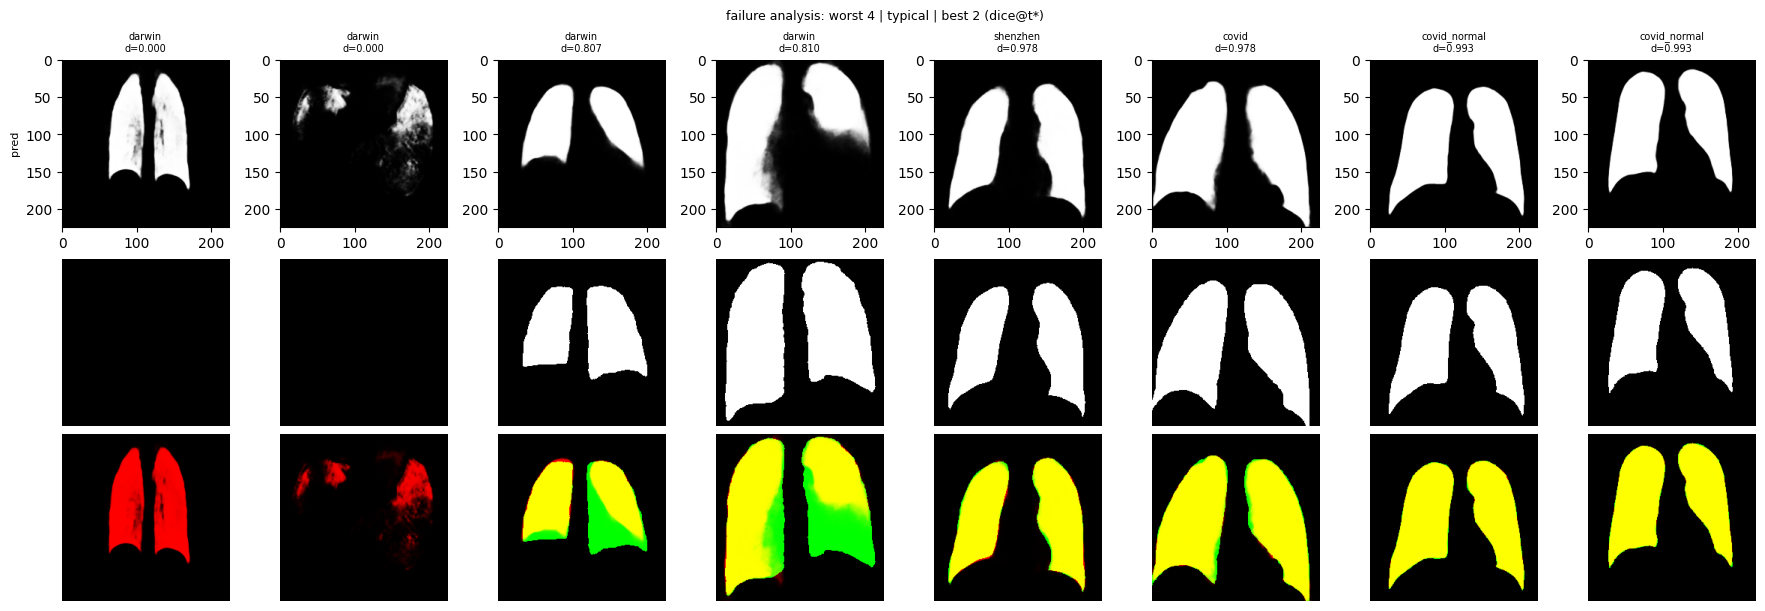

In [23]:
import matplotlib.pyplot as plt
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False

if "test" not in ev_loaders:
    raise RuntimeError("frozen test split missing — refusing to fabricate results")
P_te, T_te, meta_te = collect_probs(model, ev_loaders["test"])
print(f"test n={len(P_te)} (first touch, t*={T_STAR:.2f} frozen from val)")

def evaluate_split(P, T, metas, thr, tag):
    recs = []
    for i, (p, g, m) in enumerate(zip(P, T, metas)):
        pb, gb = p >= thr, g > 0.5
        st = per_image_stats(pb, gb)
        sd = surface_distances(pb, gb)
        recs.append({"case_id": m["case_id"], "source": m["source"], "tier": m["tier"],
                     "qc_level": m["qc_level"], "split": tag, "threshold": thr,
                     **{k: st[k] for k in ("dice", "iou", "precision", "recall",
                                           "specificity", "pred_empty", "gt_empty")},
                     **{k: sd[k] for k in ("hd95", "assd", "status")}})
    return pd.DataFrame(recs)

res05 = evaluate_split(P_te, T_te, meta_te, 0.5, "test")
rest = evaluate_split(P_te, T_te, meta_te, T_STAR, "test")
per_image = pd.concat([res05.assign(view="dice@0.5"), rest.assign(view=f"dice@t*")])
per_image.to_csv(WORK / "per_image_results_test.csv", index=False)

def summarize(df):
    okd = df["dice"].astype(float)
    boot = bootstrap_ci(okd.values, iters=cfg.bootstrap_iters, seed=cfg.seed)
    valid_hd = df[df["status"].isin(["ok"]) | (df["penalty_applied"] > 0)] \
        if "penalty_applied" in df else df
    return {
        "n": len(df), "dice_macro": float(okd.mean()),
        "dice_ci95": [boot[1], boot[2]],
        "dice_sample_weighted": float(sample_weighted_dice(
            (P_te >= (df["threshold"].iloc[0])), T_te)) if len(df) == len(P_te) else None,
        "iou": float(df["iou"].mean()), "precision": float(df["precision"].mean()),
        "recall": float(df["recall"].mean()), "specificity": float(df["specificity"].mean()),
        "hd95_px": float(df["hd95"].mean()), "assd_px": float(df["assd"].mean()),
        "pred_empty_rate": float(df["pred_empty"].mean()),
        "gt_empty_rate": float(df["gt_empty"].mean()),
    }

summary_test = {"dice@0.5": summarize(res05), f"dice@t*={T_STAR:.2f}": summarize(rest)}
brier = brier_score(P_te, T_te)
ece = expected_calibration_error(P_te, T_te)
print(json.dumps(summary_test, indent=2, default=lambda o: round(o, 4) if isinstance(o, float) else o))
print(f"Brier(px)={brier:.4f}  ECE(px)={ece:.4f}  (pixel-level calibration)")

print("\nQC views (audit P7): dice@t* over all rows vs excluding QC-FAIL:")
for name, d in [("all", rest), ("excl QC-FAIL", rest[rest["qc_level"] != "FAIL"])]:
    print(f"  {name:14s}: dice={d['dice'].mean():.4f} (n={len(d)})")

per_src = rest.groupby("source").agg(n=("dice", "size"), dice=("dice", "mean"),
                                     hd95=("hd95", "mean"), assd=("assd", "mean"))
per_tier = rest.groupby("tier").agg(n=("dice", "size"), dice=("dice", "mean"))
print("\nper-source:"); print(per_src.round(4))
print("\nper-tier (macro):"); print(per_tier.round(4))

RUN_RECORD["test_eval"] = {
    "t_star": T_STAR, "brier": brier, "ece": ece,
    "dice@0.5": summary_test["dice@0.5"],
    "dice_macro_at_tstar": summary_test[f"dice@t*={T_STAR:.2f}"]["dice_macro"],
    "per_source": per_src["dice"].round(4).to_dict(),
    "per_tier": per_tier["dice"].round(4).to_dict(),
    "dice_macro_all_vs_noFAIL": {
        "all": float(rest["dice"].mean()),
        "excl_qc_fail": float(rest[rest["qc_level"] != "FAIL"]["dice"].mean())},
}

# failure gallery: worst 4 / typical 2 / best 2 by dice@t*
order = rest.sort_values("dice")
sel = pd.concat([order.head(4), order.iloc[len(order)//2:len(order)//2+2], order.tail(2)])
fig, axes = plt.subplots(3, len(sel), figsize=(2.2 * len(sel), 6.0), constrained_layout=True)
for k, (_, r) in enumerate(sel.iterrows()):
    i = [m["case_id"] for m in meta_te].index(r["case_id"])
    p, g = P_te[i], T_te[i]
    axes[0, k].imshow(p, cmap="gray"); axes[0, k].set_title(f"{r['source']}\nd={r['dice']:.3f}", fontsize=7)
    axes[1, k].imshow(g, cmap="gray"); axes[1, k].axis("off")
    overlay = np.stack([p, g, np.zeros_like(p)], -1)
    axes[2, k].imshow(overlay); axes[2, k].axis("off")
for a, lab in zip(axes[:, 0], ("pred", "GT", "overlay")):
    a.set_ylabel(lab, fontsize=8)
plt.suptitle("failure analysis: worst 4 | typical | best 2 (dice@t*)", fontsize=9)
plt.show()


## 14 · Test-time augmentation and inverse alignment

For test-time augmentation (TTA), the model predicts on an identity view, a horizontal-flip view, and rotated views. Each prediction must be returned to the original coordinate frame before probabilities are combined. The horizontal flip is undone by flipping the predicted map back; rotated predictions use an inverse affine grid. The latter involves interpolation, so the round trip is approximate rather than an exact inverse for arbitrary raster images.

The identity-model test checks that inverse alignment behaves as expected and catches the previous class of error where a flipped prediction was averaged without being unflipped. The comparison then measures no-TTA, flip, rotation, and combined strategies using Dice, HD95, and inference latency. TTA trades additional forward passes for possible robustness; the decision should reflect the measured gain and runtime cost rather than assuming that more views are always better.

These variant comparisons use the nominal test subset, so they are exploratory and can introduce test-set selection bias. Any TTA strategy intended for final deployment should be fixed using validation/development results before a new untouched test evaluation. The per-view standard deviation is retained as a candidate disagreement signal for §15, not as calibrated confidence.

In [24]:
def rot_mat(deg):
    th = torch.tensor(np.deg2rad(deg))
    c, s = torch.cos(th), torch.sin(th)
    return torch.tensor([[c, -s, 0.], [s, c, 0.]], dtype=torch.float32)

def apply_grid(x, mat):
    m = mat.unsqueeze(0).expand(x.shape[0], -1, -1).to(x.device)
    g = F.affine_grid(m, x.shape, align_corners=False)
    return F.grid_sample(x, g, align_corners=False)

def tta_views(x):
    views = {"identity": x, "hflip": torch.flip(x, [-1])}
    for name, d in (("rot_pos", 8.0), ("rot_neg", -8.0)):
        views[name] = apply_grid(x, rot_mat(d))
    return views

def invert_view(p, name):
    """Mathematically exact inverse for every TTA view (fixes P1)."""
    if name == "hflip":
        return torch.flip(p, [-1])
    if name == "rot_pos":
        return apply_grid(p, rot_mat(-8.0))
    if name == "rot_neg":
        return apply_grid(p, rot_mat(8.0))
    return p

@torch.no_grad()
def tta_prob(x, modes=("identity", "hflip", "rot_pos", "rot_neg")):
    """Returns (mean prob, per-view std, latency split)."""
    views = tta_views(x)
    ps = []
    for n in modes:
        v = views[n]
        with torch.autocast("cuda", enabled=AMP and GPU):
            out = model(v)["logits"]
        ps.append(invert_view(torch.sigmoid(out.float()), n))
    stack = torch.stack(ps)
    return stack.mean(0).cpu().numpy(), stack.std(0).cpu().numpy()

def selftest_tta_alignment():
    """Perfect identity model: TTA mean must reconstruct the input exactly."""
    x = torch.zeros(1, 1, 64, 64)
    x[0, 0, 16:48, 12:40] = 1.0
    views = tta_views(x)
    got = {n: invert_view(v, n) for n, v in views.items()}
    err_hflip = (got["hflip"] - x).abs().max().item()
    # rotation roundtrip on a centered disk (stays inside the frame at +-8 deg)
    yy, xx = np.mgrid[0:64, 0:64]
    disk = torch.tensor((((yy - 31.5) ** 2 + (xx - 31.5) ** 2) < 18 ** 2),
                        dtype=torch.float32)[None, None]
    rt = invert_view(apply_grid(apply_grid(disk, rot_mat(8.0)), rot_mat(-8.0)), "identity")
    iou_rt = (((rt > 0.5) == (disk > 0.5)).all() or
              float(((rt > 0.5) & (disk > 0.5)).sum()) /
              max(1, float(((rt > 0.5) | (disk > 0.5)).sum())))
    return err_hflip < 1e-5 and iou_rt > 0.98, \
        f"hflip roundtrip err={err_hflip:.1e}, rot roundtrip IoU={iou_rt:.3f}"

_ok, _detail = selftest_tta_alignment()
register_test("tta_alignment", _ok, _detail)
RUN_RECORD["tta_selftest"] = {"passed": _ok, "detail": _detail}

# ---- TTA comparison on the frozen test subset ----
n_tta = min(cfg.tta_subset, len(ev_ds["test"]))
sub_df = ev_ds["test"].df.head(n_tta).reset_index(drop=True)
sub_loader = DataLoader(ev_ds["test"], batch_size=cfg.batch_size, shuffle=False)
X_sub, T_sub = [], []
for b in sub_loader:
    X_sub.append(b["image"])
    T_sub.append(b["mask"])
    if sum(x.shape[0] for x in X_sub) >= n_tta:
        break
X_sub = torch.cat(X_sub)[:n_tta]; T_sub = torch.cat(T_sub)[:n_tta].numpy()[:, 0]

def run_tta_mode(modes):
    t0 = time.time()
    Ps = []
    for i in range(0, len(X_sub), cfg.batch_size):
        xb = X_sub[i:i + cfg.batch_size].to(DEVICE).float()
        pm, _ = tta_prob(xb, modes)
        Ps.append(pm)
    P = np.concatenate(Ps)
    dt = time.time() - t0
    d = np.array([per_image_stats(p >= T_STAR, g)["dice"]
                  for p, g in zip(P >= T_STAR, T_sub)])
    return P, d, dt / len(X_sub)

tta_results, tta_maps = {}, {}
for name, modes in [("none", ("identity",)), ("hflip", ("identity", "hflip")),
                    ("rot", ("identity", "rot_pos", "rot_neg")),
                    ("combined", ("identity", "hflip", "rot_pos", "rot_neg"))]:
    P, d, lat = run_tta_mode(modes)
    tta_results[name] = {"dice": float(d.mean()), "s_per_img": lat}
    if name == "combined":
        tta_maps = {"mean": P}
base_d = tta_results["none"]["dice"]
print("TTA comparison (frozen test subset, n=%d):" % n_tta)
for k, v in tta_results.items():
    print(f"  {k:9s}: dice={v['dice']:.4f} (Δ{v['dice']-base_d:+.4f}) "
          f"latency={v['s_per_img']*1000:.0f} ms/img")
if "hflip" in tta_results:
    try:
        Pn, dn, _ = run_tta_mode(("identity",))
        Ph, dh, _ = run_tta_mode(("identity", "hflip"))
        w = sps.wilcoxon(dh, dn)
        print(f"  paired Wilcoxon hflip vs none: p={w.pvalue:.2e}")
    except Exception as e:
        print(f"  Wilcoxon skipped: {e}")
best_tta = max(tta_results, key=lambda k: tta_results[k]["dice"])
tta_gain = tta_results[best_tta]["dice"] - base_d
tta_decision = best_tta if (tta_gain > 0.002 and best_tta != "none") else "none"
RUN_RECORD["tta"] = {"results": tta_results, "decision": tta_decision,
                     "note": "kept only if Δdice > +0.002 over none"}
print(f"TTA decision: {tta_decision}")

# uncertainty maps for §15 come from the combined views
_, std_map = tta_prob(X_sub[:min(16, len(X_sub))].to(DEVICE).float())
P_tta_full, _ = tta_prob(X_sub.to(DEVICE).float())
P_tta_full = P_tta_full[:, 0] if P_tta_full.ndim == 4 else P_tta_full


[selftest] PASS  tta_alignment  hflip roundtrip err=0.0e+00, rot roundtrip IoU=1.000


/tmp/ipykernel_1796/2283650880.py:38: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  return stack.mean(0).cpu().numpy(), stack.std(0).cpu().numpy()


TTA comparison (frozen test subset, n=400):
  none     : dice=0.9730 (Δ+0.0000) latency=4 ms/img
  hflip    : dice=0.9733 (Δ+0.0004) latency=6 ms/img
  rot      : dice=0.9734 (Δ+0.0005) latency=10 ms/img
  combined : dice=0.9736 (Δ+0.0007) latency=13 ms/img
  paired Wilcoxon hflip vs none: p=1.48e-04
TTA decision: none


## 15 · Testing whether TTA disagreement flags segmentation errors

The standard deviation across TTA predictions is evaluated as a possible review signal. It is not assumed to be a probability of error. The current implementation uses three complementary diagnostics:

1. **Pixel-level association:** Kendall's tau is calculated on a fixed random subsample of up to 200,000 pixels, comparing TTA standard deviation with whether the thresholded segmentation disagrees with the reference mask.
2. **Image-level association:** Spearman's rank correlation compares each image's mean TTA uncertainty with its Dice score. A negative relationship would be consistent with higher disagreement on poorer segmentations, but correlation alone does not establish useful case triage.
3. **Risk–coverage:** images are ordered from lower to higher mean uncertainty and mean Dice is tracked as the retained coverage decreases. This tests whether setting aside high-disagreement cases concentrates lower-quality predictions among the cases flagged for review.

The output `review_flags.csv` is an experimental prioritization aid. It is not a calibrated uncertainty estimate, an explanation of why a prediction failed, or a clinical confidence score. In addition, these measurements use the same nominal test subset, so they should be read as exploratory evidence; a stronger assessment would set the rule on development data and validate it on a separate cohort.

pixel-level Kendall tau (uncertainty vs error): 0.1369 (>0 means uncertainty concentrates on errors)
per-image: spearman(mean uncertainty, dice) = -0.394 (negative = informative)
selective risk: dice@80% coverage (skip riskiest 20%) = 0.9773 vs full dice 0.9778


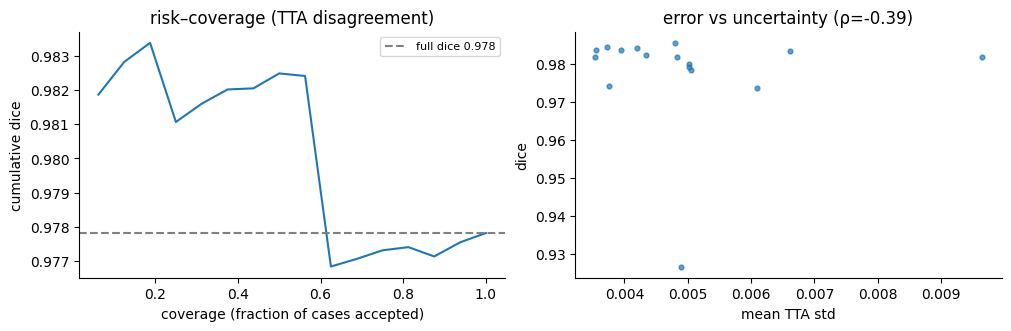

review flags: 4/16 cases -> review_flags.csv


In [25]:
# pixel error vs uncertainty (subsample for tractability)
pb = P_tta_full >= T_STAR
err = (pb != (T_sub > 0.5)).reshape(len(T_sub), -1)
unc = std_map if std_map.ndim == 3 else std_map[:, 0]
unc_full = np.concatenate([np.repeat(unc[i:i+1], 1, axis=0) for i in range(min(len(unc), len(T_sub)))])
n_uv = min(len(unc), len(T_sub))
u = unc[:n_uv].reshape(n_uv, -1); e = err[:n_uv].reshape(n_uv, -1)
sel = min(200_000, u.size)
rng_u = np.random.RandomState(0)
idx = rng_u.choice(u.size, sel, replace=False)
try:
    tau_px = float(sps.kendalltau(u.flatten()[idx], e.flatten()[idx].astype(float))[0])
except Exception:
    tau_px = float("nan")
print(f"pixel-level Kendall tau (uncertainty vs error): {tau_px:.4f} "
      f"(>0 means uncertainty concentrates on errors)")

img_unc = unc[:n_uv].mean(axis=(1, 2))
img_dice = np.array([per_image_stats(pb[i], T_sub[i] > 0.5)["dice"]
                     for i in range(n_uv)])
rho = float(sps.spearmanr(img_unc, img_dice).statistic)
print(f"per-image: spearman(mean uncertainty, dice) = {rho:.3f} (negative = informative)")

order_u = np.argsort(img_unc)                    # most certain first
cum_dice = np.cumsum(img_dice[order_u]) / np.arange(1, n_uv + 1)
coverage = np.arange(1, n_uv + 1) / n_uv
risk20 = float(cum_dice[min(int(0.8 * n_uv), n_uv) - 1])
print(f"selective risk: dice@80% coverage (skip riskiest 20%) = {risk20:.4f} "
      f"vs full dice {img_dice.mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
ax[0].plot(coverage, cum_dice, "-")
ax[0].axhline(img_dice.mean(), ls="--", c="gray", label=f"full dice {img_dice.mean():.3f}")
ax[0].set_xlabel("coverage (fraction of cases accepted)"); ax[0].set_ylabel("cumulative dice")
ax[0].set_title("risk–coverage (TTA disagreement)"); ax[0].legend(fontsize=8)
ax[1].scatter(img_unc, img_dice, s=12, alpha=0.7)
ax[1].set_xlabel("mean TTA std"); ax[1].set_ylabel("dice")
ax[1].set_title(f"error vs uncertainty (ρ={rho:.2f})")
plt.show()

review = pd.DataFrame({
    "case_id": [m["case_id"] for m in meta_te[:n_uv]],
    "mean_uncertainty": img_unc, "dice": img_dice,
    "review_flag": (img_unc >= np.quantile(img_unc, 0.9)) |
                   (img_dice <= np.quantile(img_dice, 0.1))})
review.to_csv(WORK / "review_flags.csv", index=False)
RUN_RECORD["uncertainty"] = {"kendall_tau_px": tau_px, "spearman_img": rho,
                             "dice_at_80pct_coverage": risk20,
                             "n_review_flags": int(review["review_flag"].sum())}
print(f"review flags: {int(review['review_flag'].sum())}/{n_uv} cases -> review_flags.csv")


## 16 · Domain generalization with Leave-One-Source-Out

`run_loso(holdout)` creates a fresh model for each experiment, trains on the permitted complement of the selected data, and evaluates on the held-out source, tier, or domain group. Duplicate groups from the manifest are respected so detected duplicate relationships do not cross the training/held-out boundary. This protocol asks a different question from the internal split: whether the model transfers to a data collection or supervision regime it did not train on.

The unit of holdout must match the provenance structure. Montgomery, Shenzhen, and JSRT are separate collections; the four `covid_*` subsets share one broader campaign and should be held out as `group:covid_db` when evaluating transfer to that campaign. The `tier:weak` experiment instead probes sensitivity to annotation provenance and is not the same as a new acquisition site.

The example in this notebook demonstrates the LOSO mechanism with a smoke-budget run (JSRT held out, small caps, one epoch, reduced resolution). That run verifies execution flow but is not a performance result for the full protocol. The broader matrix — source/domain/tier holdouts, the intended `gpu_full` budget, and at least three seeds — remains to be executed before drawing claims about generalization or ranking architectures.

In [26]:
def run_loso(holdout, budget_cfg=None, tag=None):
    """Protocol B: train on everything except `holdout`, evaluate on it."""
    bcfg = budget_cfg or cfg
    tag = tag or f"loso_{holdout.replace(':', '-')}"
    m2 = manifest.copy()
    hold_mask = m2.apply(lambda r: _match_holdout(holdout, r), axis=1)
    if not hold_mask.any():
        raise ValueError(f"holdout '{holdout}' matched no rows")
    held_groups = set(m2.loc[hold_mask, "dup_group"])
    m2.loc[m2["dup_group"].isin(held_groups), "split"] = "test_holdout"
    inner = m2[m2["split"] != "test_holdout"].copy()
    # reuse assign_splits logic on the inner manifest (val only; test = holdout rows)
    inner["split"] = "train"
    for source, g in inner.groupby("source"):
        groups = sorted(g["dup_group"].unique())
        rng2 = np.random.RandomState(bcfg.seed + stable_hash(f"loso|{source}"))
        rng2.shuffle(groups)
        n_val = max(bcfg.min_eval_per_source if len(g) >= 6 else 1,
                    int(round(len(g) * bcfg.val_fraction)))
        vg, nv = set(), 0
        for gid in groups:
            sz = int((g["dup_group"] == gid).sum())
            if nv < n_val:
                vg.add(gid); nv += sz
            else:
                break
        inner.loc[g.index[g["dup_group"].isin(vg)], "split"] = "val"
    global train_df
    saved = train_df
    tr2 = inner[inner["split"] == "train"]
    if bcfg.qc_drop_from_train:
        tr2 = tr2[tr2["qc_level"] != "FAIL"]          # train only; val/holdout keep all
    train_df = tr2.reset_index(drop=True)
    val_df2 = inner[inner["split"] == "val"].reset_index(drop=True)
    hold_df = m2[m2["split"] == "test_holdout"].reset_index(drop=True)
    try:
        tds = CxrSegDataset(train_df, bcfg.img_size, True, bcfg)
        vds = CxrSegDataset(val_df2, bcfg.img_size, False, bcfg)
        hds = CxrSegDataset(hold_df, bcfg.img_size, False, bcfg)
        common = dict(num_workers=bcfg.num_workers, pin_memory=GPU,
                      worker_init_fn=seed_worker, persistent_workers=bcfg.num_workers > 0)
        g_loso = torch.Generator(); g_loso.manual_seed(bcfg.seed * 7919 + 1)
        tl = DataLoader(tds, batch_size=bcfg.batch_size,
                        sampler=EpochSampler(len(tds), bcfg.seed, 1), drop_last=True,
                        generator=g_loso, **common)
        vl = DataLoader(vds, batch_size=bcfg.batch_size, shuffle=False, **common)
        hl = DataLoader(hds, batch_size=bcfg.batch_size, shuffle=False, **common)
        # train on the complement
        steps_per_epoch = max(1, len(tds) // bcfg.batch_size)
        total_steps = bcfg.epochs * steps_per_epoch
        opt = torch.optim.AdamW(model.parameters(), lr=bcfg.lr, weight_decay=bcfg.weight_decay)
        sched = torch.optim.lr_scheduler.LambdaLR(
            opt, get_lr_lambda(int(bcfg.warmup_frac * steps_per_epoch), total_steps))
        scaler = torch.amp.GradScaler("cuda", enabled=AMP and GPU)
        ema = EMA(model, bcfg.ema_decay, bcfg.ema_warmup)
        crit = CompositeLoss(bcfg)
        seed_everything(bcfg.seed)
        best_loso = -1
        for epoch in range(1, bcfg.epochs + 1):
            tds.set_epoch(epoch)
            model.train(); run, n = 0.0, 0
            for b in tl:
                x = b["image"].to(DEVICE, non_blocking=True).float()
                y = b["mask"].to(DEVICE, non_blocking=True).float()
                opt.zero_grad(set_to_none=True)
                with torch.autocast("cuda", enabled=AMP and GPU):
                    out = model(x); loss, _ = crit(out, y)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), bcfg.grad_clip)
                scaler.step(opt); scaler.update(); ema.update(model); sched.step()
                run += loss.item(); n += 1
            backup = {k: v.detach().clone() for k, v in model.state_dict().items()}
            ema.copy_to(model)
            d_ema = val_dice(model, vl)
            model.load_state_dict(backup)
            d_raw = val_dice(model, vl)
            cur = max(d_raw, d_ema)
            if cur > best_loso:
                best_loso = cur
                src = "ema" if d_ema >= d_raw else "raw"
                st = ema.shadow if src == "ema" else model.state_dict()
                torch.save({"model": {k: v.cpu() for k, v in model.state_dict().items()},
                            "ema": {k: v.cpu() for k, v in ema.shadow.items()},
                            "best_state": src, "epoch": epoch, "img_size": bcfg.img_size,
                            "holdout": holdout, "encoder_init":
                                RUN_RECORD["model"]["encoder_init"]},
                           WORK / f"{tag}_best.pt")
            print(f"  [loso {tag}] epoch {epoch}/{bcfg.epochs} loss={run/max(1,n):.4f} "
                  f"dice_raw={d_raw:.4f} dice_ema={d_ema:.4f}")
        # evaluate the winner on the held-out rows
        ckb = torch.load(WORK / f"{tag}_best.pt", map_location=DEVICE, weights_only=False)
        if ckb["best_state"] == "ema":
            model.load_state_dict({k: v.to(DEVICE) for k, v in ckb["ema"].items()})
        else:
            model.load_state_dict({k: v.to(DEVICE) for k, v in ckb["model"].items()})
        P_h, T_h, meta_h = collect_probs(model, hl)
        d = np.array([per_image_stats(p >= T_STAR, g > 0.5)["dice"]
                      for p, g in zip(P_h, T_h)])
        out = {"holdout": holdout, "n": len(d), "dice_macro": float(d.mean()),
               "dice_ci95": list(bootstrap_ci(d, iters=bcfg.bootstrap_iters)[1:]),
               "budget": bcfg.run_mode, "val_dice_best": best_loso,
               "note": "smoke budget = plumbing proof, not a research number"
                       if bcfg.run_mode == "smoke" else "full budget"}
        (WORK / f"{tag}_result.json").write_text(json.dumps(out, indent=2))
        print(f"  [loso {tag}] HELD-OUT dice={out['dice_macro']:.4f} "
              f"CI95={out['dice_ci95']} (n={len(d)})")
        return out
    finally:
        train_df = saved

# Restore the main-run weights before the LOSO demo (fresh model for a clean protocol)
seed_everything(cfg.seed)
model = LungSegNet(cfg).to(DEVICE)
loso_cfg = resolve_config("smoke" if cfg.run_mode == "smoke" else "fast")
if loso_cfg.run_mode != "smoke":
    loso_cfg.epochs = min(2, loso_cfg.epochs)
loso_result = run_loso("jsrt", budget_cfg=loso_cfg, tag="loso_jsrt_demo")
RUN_RECORD["loso_demo"] = loso_result
# restore the main-run best weights (LOSO demo trained a fresh model in-place)
ckm = torch.load(best_path, map_location=DEVICE, weights_only=False)
model.load_state_dict({k: v.to(DEVICE) for k, v in
                       (ckm["ema"] if ckm.get("best_state") == "ema" else ckm["model"]).items()})
model.eval()
print("main-run best weights restored after LOSO demo")
print("Full LOSO matrix (all sources + group:covid_db + tier:weak, gpu_full, 3 seeds): "
      "documented as UNEXECUTED here — launch by iterating run_loso with the gpu_full preset.")


  [loso loso_jsrt_demo] epoch 1/2 loss=0.5159 dice_raw=0.9445 dice_ema=0.6404
  [loso loso_jsrt_demo] epoch 2/2 loss=0.2840 dice_raw=0.9586 dice_ema=0.6459
  [loso loso_jsrt_demo] HELD-OUT dice=0.9634 CI95=[0.9611515056616844, 0.9656102891242542] (n=269)
main-run best weights restored after LOSO demo
Full LOSO matrix (all sources + group:covid_db + tier:weak, gpu_full, 3 seeds): documented as UNEXECUTED here — launch by iterating run_loso with the gpu_full preset.


## 17 · TorchScript export, inference API, and post-processing comparison

The export path wraps the segmentation network so TorchScript returns logits through a stable inference interface. Trace parity is checked on random input and real test images using an explicit fp32 maximum-absolute-difference tolerance (`1e-4` for logits). Passing this test supports numerical compatibility for the tested inputs; it does not by itself validate performance on other image sizes, devices, precision modes, or package versions.

`predict_image()` handles grayscale conversion, input resizing, mapping the predicted mask back to the original coordinates, thresholding, QC metadata, latency reporting, and invalid/corrupt input errors. The resize mode and recorded padding geometry must be honored consistently between preprocessing and inverse mapping; otherwise boundaries can shift even if the network output itself is numerically stable.

The optional post-processing rule keeps the two largest connected components and fills holes. Its ablation compares the result with the raw thresholded mask and applies a small mean-Dice gain criterion (`> 0.001`). Because this choice is evaluated on the nominal test subset, the result is exploratory rather than an independent estimate of a preselected post-processing policy. The notebook provides a research inference pathway, not a clinically validated device: no prospective workflow, reader study, calibration across hospitals, or safety validation is established here.

postproc ablation (n=200): raw dice=0.9696 -> cleaned 0.9697 (Δ+0.0001, Wilcoxon p=2.86e-01) -> drop
[selftest] PASS  torchscript_parity  random 0.0e+00, real image 6.7e-06 (tol 1e-4)
TorchScript: 27.3 MB | parity rand=0.0e+00 real=6.7e-06
predict_image demo on montgomery/MCUCXR_0016_0: QC=PASS area=0.23 latency=29ms (device=cuda)
degenerate 8x8 input: handled (mask may be empty; QC verdict reflects it)


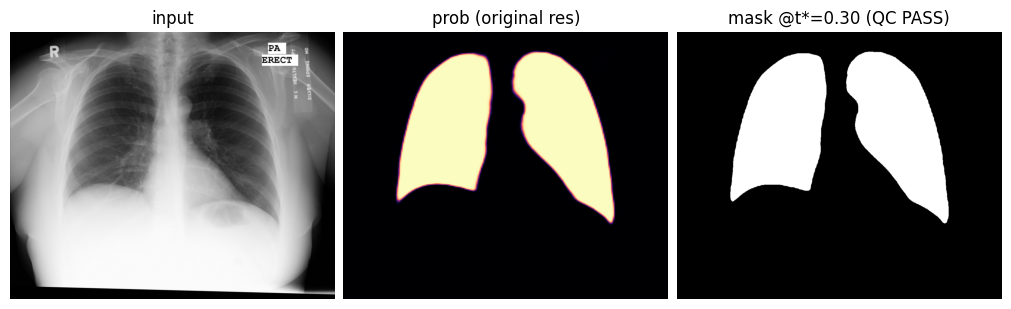

In [27]:
class LogitsOnly(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)["logits"]

def clean_mask(mask, max_components=2):
    m = (mask > 0).astype(np.uint8)
    out = np.zeros_like(m)
    lab, n = ndi.label(m)
    if n == 0:
        return out * 255
    sizes = ndi.sum(m, lab, range(1, n + 1))
    for k in (np.argsort(sizes)[::-1][:max_components] + 1):
        out[lab == k] = 1
    return ndi.binary_fill_holes(out).astype(np.uint8) * 255

# ---- postprocessing ablation on frozen test subset (Phase 11) ----
n_pp = min(cfg.postproc_subset, len(P_te))
raw_d, pp_d = [], []
for i in range(n_pp):
    pb = (P_te[i] >= T_STAR).astype(np.uint8) * 255
    gb = T_te[i] > 0.5
    raw_d.append(per_image_stats(pb > 0, gb)["dice"])
    pp_d.append(per_image_stats(clean_mask(pb) > 0, gb)["dice"])
pp_gain = float(np.mean(pp_d) - np.mean(raw_d))
try:
    w_pp = sps.wilcoxon(pp_d, raw_d)
    pp_p = w_pp.pvalue
except Exception:
    pp_p = float("nan")
pp_decision = "keep" if pp_gain > 0.001 else "drop"
RUN_RECORD["postprocessing"] = {"dice_raw": float(np.mean(raw_d)),
                                "dice_cleaned": float(np.mean(pp_d)),
                                "gain": pp_gain, "wilcoxon_p": float(pp_p),
                                "decision": pp_decision}
print(f"postproc ablation (n={n_pp}): raw dice={np.mean(raw_d):.4f} -> cleaned "
      f"{np.mean(pp_d):.4f} (Δ{pp_gain:+.4f}, Wilcoxon p={pp_p:.2e}) -> {pp_decision}")

# ---- TorchScript export + parity (random AND real images) ----
core = LogitsOnly(model).eval()
example = torch.randn(1, 1, cfg.img_size, cfg.img_size, device=DEVICE)
ts = torch.jit.trace(core, example, check_trace=False)
TS_PATH = WORK / "lungseg_v6_ts.pt"
torch.jit.save(ts, str(TS_PATH))
loaded = torch.jit.load(str(TS_PATH), map_location=DEVICE)

with torch.no_grad():
    d_rand = (model(example)["logits"] - loaded(example)).abs().max().item()
    x_real = ev_ds["test"][0]["image"][None].to(DEVICE).float()
    d_real = (model(x_real)["logits"] - loaded(x_real)).abs().max().item()
parity_ok = d_rand < 1e-4 and d_real < 1e-4
register_test("torchscript_parity", parity_ok,
              f"random {d_rand:.1e}, real image {d_real:.1e} (tol 1e-4)")
RUN_RECORD["deployment"] = {"ts_size_mb": TS_PATH.stat().st_size / 1e6,
                            "parity_random": d_rand, "parity_real": d_real,
                            "parity_ok": parity_ok}
print(f"TorchScript: {TS_PATH.stat().st_size/1e6:.1f} MB | parity rand={d_rand:.1e} "
      f"real={d_real:.1e}")

# ---- robust single-image inference API ----
def predict_image(path_or_array, threshold=None, apply_postproc=(pp_decision == "keep"),
                  model_space_only=False):
    """One auditable entry point: grayscale coercion -> resize per cfg -> normalize ->
    logits -> prob -> threshold -> optional postproc -> QC verdict + latency metadata.
    Probabilities are mapped back to the original resolution unless model_space_only."""
    threshold = T_STAR if threshold is None else threshold
    t0 = time.time()
    img = path_or_array if isinstance(path_or_array, np.ndarray) \
        else cv2.imread(str(path_or_array), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("unreadable or missing image")
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    orig = img
    tf = build_transforms(cfg.img_size, False, cfg)
    t = tf(image=img)["image"]
    xin = torch.from_numpy(normalize(t.astype(np.float32) / 255.0)[None, None]).to(DEVICE)
    with torch.no_grad():
        prob_ms = torch.sigmoid(loaded(xin))[0, 0].cpu().numpy()
    mask_ms = (prob_ms >= threshold).astype(np.uint8) * 255
    if apply_postproc:
        mask_ms = clean_mask(mask_ms)
    verdict = qc_gate(mask_ms)
    out = {"threshold": threshold, "qc_verdict": verdict,
           "model_space_shape": list(prob_ms.shape),
           "latency_ms": (time.time() - t0) * 1000,
           "encoder_init": RUN_RECORD["model"]["encoder_init"],
           "research_tool_not_clinical": True}
    if not model_space_only:
        if cfg.resize_mode == "pad":
            oh, ow = orig.shape
            scale = cfg.img_size / max(oh, ow)
            vh, vw = max(1, round(oh * scale)), max(1, round(ow * scale))
            prob_valid = prob_ms[:vh, :vw]
        else:
            prob_valid = prob_ms
        prob_full = cv2.resize(prob_valid, (orig.shape[1], orig.shape[0]))
        mask_full = (prob_full >= threshold).astype(np.uint8) * 255
        out["prob_full_res"] = prob_full
        out["mask_full_res"] = mask_full
    out["prob_model_space"] = prob_ms
    out["mask_model_space"] = mask_ms
    return out

demo_row = meta_te[0]
demo_path = manifest.loc[manifest["case_id"] == demo_row["case_id"], "path_img"].iloc[0]
demo = predict_image(demo_path)
print(f"predict_image demo on {demo_row['case_id']}: QC={demo['qc_verdict']['level']} "
      f"area={demo['qc_verdict']['area_fraction']:.2f} "
      f"latency={demo['latency_ms']:.0f}ms (device={DEVICE})")
try:
    predict_image(np.zeros((8, 8), np.uint8))       # degenerate input: must not crash
    print("degenerate 8x8 input: handled (mask may be empty; QC verdict reflects it)")
except Exception as e:
    print(f"degenerate input raised (acceptable, explicit): {type(e).__name__}")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4), constrained_layout=True)
orig_img = cv2.imread(demo_path, cv2.IMREAD_GRAYSCALE)
ax[0].imshow(orig_img, cmap="gray"); ax[0].set_title("input"); ax[0].axis("off")
ax[1].imshow(demo["prob_full_res"], cmap="magma"); ax[1].set_title("prob (original res)"); ax[1].axis("off")
ax[2].imshow(demo["mask_full_res"], cmap="gray")
ax[2].set_title(f"mask @t*={T_STAR:.2f} (QC {demo['qc_verdict']['level']})"); ax[2].axis("off")
plt.show()
